# Dự đoán giá nhà House Prices

## Phần 1. Đọc và chuẩn bị dữ liệu

In [4]:
# Nạp các thư viện cơ bản
import pandas as pd
import numpy as np

In [5]:
# Khai báo đường dẫn tới file train và test trên Kaggle
train_path = '/kaggle/input/competitions/house-prices-advanced-regression-techniques/train.csv'
test_path = '/kaggle/input/competitions/house-prices-advanced-regression-techniques/test.csv'

In [6]:
# Đọc hai file csv thành DataFrame
train_hp = pd.read_csv(train_path)
test_hp = pd.read_csv(test_path)

In [7]:
# In kích thước hai tập dữ liệu
print("Kích thước tập Train giá nhà:", train_hp.shape)
print("Kích thước tập Test giá nhà:", test_hp.shape)

Kích thước tập Train giá nhà: (1460, 81)
Kích thước tập Test giá nhà: (1459, 80)


In [8]:
# Đếm số lượng và tỷ lệ phần trăm giá trị thiếu ở mỗi cột của tập train
missing_count = train_hp.isnull().sum()
missing_percent = (train_hp.isnull().sum() / len(train_hp)) * 100

In [9]:
# Gộp thành một bảng và chỉ giữ các cột thực sự có giá trị thiếu
missing_df = pd.DataFrame({
    'Số lượng thiếu': missing_count,
    'Tỷ lệ phần trăm (%)': missing_percent
})
missing_df = missing_df[missing_df['Số lượng thiếu'] > 0].sort_values(by='Số lượng thiếu', ascending=False)

In [10]:
# Xem 15 cột thiếu nhiều nhất
print("Top các cột bị thiếu dữ liệu trong tập Train:")
display(missing_df.head(15))

Top các cột bị thiếu dữ liệu trong tập Train:


,Số lượng thiếu,Tỷ lệ phần trăm (%)
PoolQC,1453,99.520548
MiscFeature,1406,96.301370
Alley,1369,93.767123
Fence,1179,80.753425
MasVnrType,872,59.726027
FireplaceQu,690,47.260274
LotFrontage,259,17.739726
GarageType,81,5.547945
GarageYrBlt,81,5.547945
GarageFinish,81,5.547945


In [11]:
# Các cột dạng chữ mà giá trị thiếu có nghĩa là không có tiện ích đó
cols_cat_none = [
    'PoolQC', 'MiscFeature', 'Alley', 'Fence', 'FireplaceQu',
    'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond',
    'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2',
    'MasVnrType'
]

In [12]:
# Điền chữ None cho các cột này ở cả tập train và tập test
for col in cols_cat_none:
    if col in train_hp.columns:
        train_hp[col] = train_hp[col].fillna('None')
    if col in test_hp.columns:
        test_hp[col] = test_hp[col].fillna('None')

In [13]:
# Các cột số liên quan đến gara và tầng hầm, thiếu nghĩa là bằng 0
cols_num_zero = ['GarageYrBlt', 'GarageArea', 'GarageCars', 'BsmtFinSF1', 'BsmtFinSF2',
                 'BsmtUnfSF', 'TotalBsmtSF', 'BsmtFullBath', 'BsmtHalfBath', 'MasVnrArea']

for col in cols_num_zero:
    if col in train_hp.columns:
        train_hp[col] = train_hp[col].fillna(0)
    if col in test_hp.columns:
        test_hp[col] = test_hp[col].fillna(0)

In [14]:
# Cột LotFrontage thiếu thì điền bằng trung vị của tập train
if 'LotFrontage' in train_hp.columns:
    median_lot = train_hp['LotFrontage'].median()
    train_hp['LotFrontage'] = train_hp['LotFrontage'].fillna(median_lot)
    test_hp['LotFrontage'] = test_hp['LotFrontage'].fillna(median_lot)

In [15]:
# Kiểm tra còn bao nhiêu ô thiếu
con_thieu_train = train_hp.isnull().sum().sum()
con_thieu_test = test_hp.isnull().sum().sum()

print(f"Tổng số ô còn thiếu dữ liệu trong tập Train: {con_thieu_train}")
print(f"Tổng số ô còn thiếu dữ liệu trong tập Test: {con_thieu_test}")

Tổng số ô còn thiếu dữ liệu trong tập Train: 1
Tổng số ô còn thiếu dữ liệu trong tập Test: 12


In [16]:
# Điền nốt các cột số còn sót lại bằng trung vị của tập train
cols_num_train = train_hp.select_dtypes(include=['int64', 'float64']).columns
for col in cols_num_train:
    if train_hp[col].isnull().sum() > 0:
        median_val = train_hp[col].median()
        train_hp[col] = train_hp[col].fillna(median_val)

In [17]:
# Điền cho tập test bằng trung vị của tập train để tránh rò rỉ dữ liệu
cols_num_test = test_hp.select_dtypes(include=['int64', 'float64']).columns
for col in cols_num_test:
    if test_hp[col].isnull().sum() > 0:
        median_val = train_hp[col].median()
        test_hp[col] = test_hp[col].fillna(median_val)

In [18]:
# Điền nốt các cột chữ còn sót lại bằng giá trị xuất hiện nhiều nhất của tập train
cols_cat_train = train_hp.select_dtypes(include=['object']).columns
for col in cols_cat_train:
    if train_hp[col].isnull().sum() > 0:
        mode_val = train_hp[col].mode()[0]
        train_hp[col] = train_hp[col].fillna(mode_val)

cols_cat_test = test_hp.select_dtypes(include=['object']).columns
for col in cols_cat_test:
    if test_hp[col].isnull().sum() > 0:
        mode_val = train_hp[col].mode()[0]
        test_hp[col] = test_hp[col].fillna(mode_val)

In [19]:
# Kiểm tra lần cuối xem còn ô trống nào không
print("Tổng số ô còn thiếu sau khi xử lý - Train:", train_hp.isnull().sum().sum())
print("Tổng số ô còn thiếu sau khi xử lý - Test:", test_hp.isnull().sum().sum())

Tổng số ô còn thiếu sau khi xử lý - Train: 0
Tổng số ô còn thiếu sau khi xử lý - Test: 0


In [20]:
# Tách biến mục tiêu SalePrice ra khỏi tập train
y_train = train_hp['SalePrice']

# Bỏ cột Id vì Id không giúp ích cho việc dự đoán
X_train = train_hp.drop(columns=['SalePrice', 'Id'])
X_test = test_hp.drop(columns=['Id'])

In [21]:
# Gộp train và test lại để mã hóa One-Hot đồng nhất các cột
df_combined = pd.concat([X_train, X_test], axis=0)
df_combined_encoded = pd.get_dummies(df_combined)

In [22]:
# Tách trở lại thành tập train và tập test
X_train_final = df_combined_encoded.iloc[:len(train_hp)]
X_test_final = df_combined_encoded.iloc[len(train_hp):]

print("Kích thước X_train sau khi mã hóa:", X_train_final.shape)
print("Kích thước X_test sau khi mã hóa:", X_test_final.shape)

Kích thước X_train sau khi mã hóa: (1460, 302)
Kích thước X_test sau khi mã hóa: (1459, 302)


In [23]:
# Chia tập train thành 80% để học và 20% để kiểm tra
from sklearn.model_selection import train_test_split

X_tr, X_val, y_tr, y_val = train_test_split(
    X_train_final,
    y_train,
    test_size=0.2,
    random_state=42
)

print("Kích thước tập huấn luyện X_tr:", X_tr.shape)
print("Kích thước tập kiểm tra X_val:", X_val.shape)

Kích thước tập huấn luyện X_tr: (1168, 302)
Kích thước tập kiểm tra X_val: (292, 302)


## Phần 2. Huấn luyện các mô hình

In [24]:
# Nạp hàm tính sai số dùng chung cho mọi mô hình
from sklearn.metrics import mean_squared_error

### 2.1. Ridge Regression

In [25]:
# Nạp mô hình và khởi tạo mô hình tuyến tính có điều chuẩn, dùng làm mốc so sánh
from sklearn.linear_model import Ridge

model_ridge = Ridge(alpha=1.0, random_state=42)

In [26]:
# Huấn luyện trên 80% dữ liệu
print("Đang huấn luyện Ridge Regression...")
model_ridge.fit(X_tr, y_tr)
print("Huấn luyện xong")

Đang huấn luyện Ridge Regression...
Huấn luyện xong


In [27]:
# Dự đoán trên tập validation và tính sai số RMSE
y_pred_val_model_ridge = model_ridge.predict(X_val)
rmse_val_model_ridge = np.sqrt(mean_squared_error(y_val, y_pred_val_model_ridge))
print(f"Sai số RMSE của Ridge Regression trên tập Validation: {rmse_val_model_ridge:.4f}")

Sai số RMSE của Ridge Regression trên tập Validation: 29737.2316


In [28]:
# Huấn luyện lại trên toàn bộ dữ liệu train để dự đoán tập test
print("Đang huấn luyện lại Ridge Regression trên toàn bộ dữ liệu...")
model_ridge.fit(X_train_final, y_train)
print("Huấn luyện lại xong")

Đang huấn luyện lại Ridge Regression trên toàn bộ dữ liệu...
Huấn luyện lại xong


In [29]:
# Dự đoán giá nhà cho tập test và lưu file nộp bài
y_test_pred_model_ridge = model_ridge.predict(X_test_final)

sub = pd.DataFrame({
    'Id': test_hp['Id'],
    'SalePrice': y_test_pred_model_ridge
})

sub.to_csv('submission_ridge.csv', index=False)
print("Đã xuất file submission_ridge.csv")

Đã xuất file submission_ridge.csv


### 2.2. Random Forest

In [30]:
# Nạp mô hình và khởi tạo
from sklearn.ensemble import RandomForestRegressor

model_rf = RandomForestRegressor(n_estimators=100, random_state=42)

In [31]:
# Huấn luyện trên 80% dữ liệu
print("Đang huấn luyện Random Forest...")
model_rf.fit(X_tr, y_tr)
print("Huấn luyện xong")

Đang huấn luyện Random Forest...
Huấn luyện xong


In [32]:
# Dự đoán trên tập validation và tính sai số RMSE
y_pred_val_model_rf = model_rf.predict(X_val)
rmse_val_model_rf = np.sqrt(mean_squared_error(y_val, y_pred_val_model_rf))
print(f"Sai số RMSE của Random Forest trên tập Validation: {rmse_val_model_rf:.4f}")

Sai số RMSE của Random Forest trên tập Validation: 28713.8284


In [33]:
# Huấn luyện lại trên toàn bộ dữ liệu train để dự đoán tập test
print("Đang huấn luyện lại Random Forest trên toàn bộ dữ liệu...")
model_rf.fit(X_train_final, y_train)
print("Huấn luyện lại xong")

Đang huấn luyện lại Random Forest trên toàn bộ dữ liệu...
Huấn luyện lại xong


In [34]:
# Dự đoán giá nhà cho tập test và lưu file nộp bài
y_test_pred_model_rf = model_rf.predict(X_test_final)

sub = pd.DataFrame({
    'Id': test_hp['Id'],
    'SalePrice': y_test_pred_model_rf
})

sub.to_csv('submission_random_forest.csv', index=False)
print("Đã xuất file submission_random_forest.csv")

Đã xuất file submission_random_forest.csv


### 2.3. Decision Tree

In [35]:
# Nạp mô hình và khởi tạo
from sklearn.tree import DecisionTreeRegressor

model_dt = DecisionTreeRegressor(random_state=42)

In [36]:
# Huấn luyện trên 80% dữ liệu
print("Đang huấn luyện Decision Tree...")
model_dt.fit(X_tr, y_tr)
print("Huấn luyện xong")

Đang huấn luyện Decision Tree...
Huấn luyện xong


In [37]:
# Dự đoán trên tập validation và tính sai số RMSE
y_pred_val_model_dt = model_dt.predict(X_val)
rmse_val_model_dt = np.sqrt(mean_squared_error(y_val, y_pred_val_model_dt))
print(f"Sai số RMSE của Decision Tree trên tập Validation: {rmse_val_model_dt:.4f}")

Sai số RMSE của Decision Tree trên tập Validation: 43357.9876


In [38]:
# Huấn luyện lại trên toàn bộ dữ liệu train để dự đoán tập test
print("Đang huấn luyện lại Decision Tree trên toàn bộ dữ liệu...")
model_dt.fit(X_train_final, y_train)
print("Huấn luyện lại xong")

Đang huấn luyện lại Decision Tree trên toàn bộ dữ liệu...
Huấn luyện lại xong


In [39]:
# Dự đoán giá nhà cho tập test và lưu file nộp bài
y_test_pred_model_dt = model_dt.predict(X_test_final)

sub = pd.DataFrame({
    'Id': test_hp['Id'],
    'SalePrice': y_test_pred_model_dt
})

sub.to_csv('submission_decision_tree.csv', index=False)
print("Đã xuất file submission_decision_tree.csv")

Đã xuất file submission_decision_tree.csv


### 2.4. Extra Trees

In [40]:
# Nạp mô hình và khởi tạo
from sklearn.ensemble import ExtraTreesRegressor

model_et = ExtraTreesRegressor(n_estimators=100, random_state=42)

In [41]:
# Huấn luyện trên 80% dữ liệu
print("Đang huấn luyện Extra Trees...")
model_et.fit(X_tr, y_tr)
print("Huấn luyện xong")

Đang huấn luyện Extra Trees...
Huấn luyện xong


In [42]:
# Dự đoán trên tập validation và tính sai số RMSE
y_pred_val_model_et = model_et.predict(X_val)
rmse_val_model_et = np.sqrt(mean_squared_error(y_val, y_pred_val_model_et))
print(f"Sai số RMSE của Extra Trees trên tập Validation: {rmse_val_model_et:.4f}")

Sai số RMSE của Extra Trees trên tập Validation: 28205.1827


In [43]:
# Huấn luyện lại trên toàn bộ dữ liệu train để dự đoán tập test
print("Đang huấn luyện lại Extra Trees trên toàn bộ dữ liệu...")
model_et.fit(X_train_final, y_train)
print("Huấn luyện lại xong")

Đang huấn luyện lại Extra Trees trên toàn bộ dữ liệu...
Huấn luyện lại xong


In [44]:
# Dự đoán giá nhà cho tập test và lưu file nộp bài
y_test_pred_model_et = model_et.predict(X_test_final)

sub = pd.DataFrame({
    'Id': test_hp['Id'],
    'SalePrice': y_test_pred_model_et
})

sub.to_csv('submission_extra_trees.csv', index=False)
print("Đã xuất file submission_extra_trees.csv")

Đã xuất file submission_extra_trees.csv


### 2.5. Gradient Boosting

In [45]:
# Nạp mô hình và khởi tạo
from sklearn.ensemble import GradientBoostingRegressor

model_gb = GradientBoostingRegressor(n_estimators=100, random_state=42)

In [46]:
# Huấn luyện trên 80% dữ liệu
print("Đang huấn luyện Gradient Boosting...")
model_gb.fit(X_tr, y_tr)
print("Huấn luyện xong")

Đang huấn luyện Gradient Boosting...
Huấn luyện xong


In [47]:
# Dự đoán trên tập validation và tính sai số RMSE
y_pred_val_model_gb = model_gb.predict(X_val)
rmse_val_model_gb = np.sqrt(mean_squared_error(y_val, y_pred_val_model_gb))
print(f"Sai số RMSE của Gradient Boosting trên tập Validation: {rmse_val_model_gb:.4f}")

Sai số RMSE của Gradient Boosting trên tập Validation: 27819.8655


In [48]:
# Huấn luyện lại trên toàn bộ dữ liệu train để dự đoán tập test
print("Đang huấn luyện lại Gradient Boosting trên toàn bộ dữ liệu...")
model_gb.fit(X_train_final, y_train)
print("Huấn luyện lại xong")

Đang huấn luyện lại Gradient Boosting trên toàn bộ dữ liệu...
Huấn luyện lại xong


In [49]:
# Dự đoán giá nhà cho tập test và lưu file nộp bài
y_test_pred_model_gb = model_gb.predict(X_test_final)

sub = pd.DataFrame({
    'Id': test_hp['Id'],
    'SalePrice': y_test_pred_model_gb
})

sub.to_csv('submission_gradient_boosting.csv', index=False)
print("Đã xuất file submission_gradient_boosting.csv")

Đã xuất file submission_gradient_boosting.csv


### 2.6. AdaBoost

In [50]:
# Nạp mô hình và khởi tạo
from sklearn.ensemble import AdaBoostRegressor

model_ab = AdaBoostRegressor(random_state=42)

In [51]:
# Huấn luyện trên 80% dữ liệu
print("Đang huấn luyện AdaBoost...")
model_ab.fit(X_tr, y_tr)
print("Huấn luyện xong")

Đang huấn luyện AdaBoost...
Huấn luyện xong


In [52]:
# Dự đoán trên tập validation và tính sai số RMSE
y_pred_val_model_ab = model_ab.predict(X_val)
rmse_val_model_ab = np.sqrt(mean_squared_error(y_val, y_pred_val_model_ab))
print(f"Sai số RMSE của AdaBoost trên tập Validation: {rmse_val_model_ab:.4f}")

Sai số RMSE của AdaBoost trên tập Validation: 36134.0073


In [53]:
# Huấn luyện lại trên toàn bộ dữ liệu train để dự đoán tập test
print("Đang huấn luyện lại AdaBoost trên toàn bộ dữ liệu...")
model_ab.fit(X_train_final, y_train)
print("Huấn luyện lại xong")

Đang huấn luyện lại AdaBoost trên toàn bộ dữ liệu...
Huấn luyện lại xong


In [54]:
# Dự đoán giá nhà cho tập test và lưu file nộp bài
y_test_pred_model_ab = model_ab.predict(X_test_final)

sub = pd.DataFrame({
    'Id': test_hp['Id'],
    'SalePrice': y_test_pred_model_ab
})

sub.to_csv('submission_adaboost.csv', index=False)
print("Đã xuất file submission_adaboost.csv")

Đã xuất file submission_adaboost.csv


### 2.7. KNN

In [55]:
# Nạp mô hình và khởi tạo với số láng giềng k bằng 5
from sklearn.neighbors import KNeighborsRegressor

model_knn = KNeighborsRegressor(n_neighbors=5)

In [56]:
# Huấn luyện trên 80% dữ liệu
print("Đang huấn luyện KNN...")
model_knn.fit(X_tr, y_tr)
print("Huấn luyện xong")

Đang huấn luyện KNN...
Huấn luyện xong


In [57]:
# Dự đoán trên tập validation và tính sai số RMSE
y_pred_val_model_knn = model_knn.predict(X_val)
rmse_val_model_knn = np.sqrt(mean_squared_error(y_val, y_pred_val_model_knn))
print(f"Sai số RMSE của KNN trên tập Validation: {rmse_val_model_knn:.4f}")

Sai số RMSE của KNN trên tập Validation: 47943.5569


In [58]:
# Huấn luyện lại trên toàn bộ dữ liệu train để dự đoán tập test
print("Đang huấn luyện lại KNN trên toàn bộ dữ liệu...")
model_knn.fit(X_train_final, y_train)
print("Huấn luyện lại xong")

Đang huấn luyện lại KNN trên toàn bộ dữ liệu...
Huấn luyện lại xong


In [59]:
# Dự đoán giá nhà cho tập test và lưu file nộp bài
y_test_pred_model_knn = model_knn.predict(X_test_final)

sub = pd.DataFrame({
    'Id': test_hp['Id'],
    'SalePrice': y_test_pred_model_knn
})

sub.to_csv('submission_knn.csv', index=False)
print("Đã xuất file submission_knn.csv")

Đã xuất file submission_knn.csv


### 2.8. SVR

In [60]:
# Nạp mô hình và khởi tạo kèm bước chuẩn hóa dữ liệu
from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

model_svr = make_pipeline(StandardScaler(with_mean=False), SVR())

In [61]:
# Huấn luyện trên 80% dữ liệu
print("Đang huấn luyện SVR...")
model_svr.fit(X_tr, y_tr)
print("Huấn luyện xong")

Đang huấn luyện SVR...
Huấn luyện xong


In [62]:
# Dự đoán trên tập validation và tính sai số RMSE
y_pred_val_model_svr = model_svr.predict(X_val)
rmse_val_model_svr = np.sqrt(mean_squared_error(y_val, y_pred_val_model_svr))
print(f"Sai số RMSE của SVR trên tập Validation: {rmse_val_model_svr:.4f}")

Sai số RMSE của SVR trên tập Validation: 88667.1712


In [63]:
# Huấn luyện lại trên toàn bộ dữ liệu train để dự đoán tập test
print("Đang huấn luyện lại SVR trên toàn bộ dữ liệu...")
model_svr.fit(X_train_final, y_train)
print("Huấn luyện lại xong")

Đang huấn luyện lại SVR trên toàn bộ dữ liệu...
Huấn luyện lại xong


In [64]:
# Dự đoán giá nhà cho tập test và lưu file nộp bài
y_test_pred_model_svr = model_svr.predict(X_test_final)

sub = pd.DataFrame({
    'Id': test_hp['Id'],
    'SalePrice': y_test_pred_model_svr
})

sub.to_csv('submission_svr.csv', index=False)
print("Đã xuất file submission_svr.csv")

Đã xuất file submission_svr.csv


### 2.9. MLP Regressor

In [65]:
# Nạp mô hình và khởi tạo kèm bước chuẩn hóa dữ liệu
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

model_mlp = make_pipeline(
    StandardScaler(with_mean=False),
    MLPRegressor(hidden_layer_sizes=(100, 50), max_iter=500, random_state=42)
)

In [66]:
# Huấn luyện trên 80% dữ liệu
print("Đang huấn luyện MLP Regressor...")
model_mlp.fit(X_tr, y_tr)
print("Huấn luyện xong")

Đang huấn luyện MLP Regressor...
Huấn luyện xong


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


In [67]:
# Dự đoán trên tập validation và tính sai số RMSE
y_pred_val_model_mlp = model_mlp.predict(X_val)
rmse_val_model_mlp = np.sqrt(mean_squared_error(y_val, y_pred_val_model_mlp))
print(f"Sai số RMSE của MLP Regressor trên tập Validation: {rmse_val_model_mlp:.4f}")

Sai số RMSE của MLP Regressor trên tập Validation: 38795.6893


In [68]:
# Huấn luyện lại trên toàn bộ dữ liệu train để dự đoán tập test
print("Đang huấn luyện lại MLP Regressor trên toàn bộ dữ liệu...")
model_mlp.fit(X_train_final, y_train)
print("Huấn luyện lại xong")

Đang huấn luyện lại MLP Regressor trên toàn bộ dữ liệu...
Huấn luyện lại xong


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


In [69]:
# Dự đoán giá nhà cho tập test và lưu file nộp bài
y_test_pred_model_mlp = model_mlp.predict(X_test_final)

sub = pd.DataFrame({
    'Id': test_hp['Id'],
    'SalePrice': y_test_pred_model_mlp
})

sub.to_csv('submission_mlp.csv', index=False)
print("Đã xuất file submission_mlp.csv")

Đã xuất file submission_mlp.csv


## Phần 3. Vẽ hình minh họa cho báo cáo

Các hình được lưu vào thư mục `hinh_bao_cao` ở dạng PNG 300 dpi.

Lưu ý: các mô hình ở Phần 2 đã được huấn luyện lại trên toàn bộ dữ liệu nên đã nhìn thấy tập validation.
Vì vậy ở Phần 3 ta clone lại mô hình và chỉ huấn luyện trên 80% dữ liệu để đánh giá cho công bằng.

### 3.0. Thiết lập chung

In [70]:
# Nạp các thư viện vẽ hình và đánh giá
import os
import time
import warnings
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.linear_model import Ridge
from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import learning_curve

# Tắt các cảnh báo cho gọn màn hình
warnings.filterwarnings("ignore")

In [71]:
# Tạo thư mục chứa hình
THU_MUC = "hinh_bao_cao"
os.makedirs(THU_MUC, exist_ok=True)

# Chọn kiểu nền cho hình
sns.set_theme(style="whitegrid")

In [72]:
# Hàm lưu hình ra file PNG rồi hiển thị lên màn hình
def luu(fig, ten):
    fig.savefig(f"{THU_MUC}/{ten}.png", dpi=300, bbox_inches="tight")
    plt.show()

In [73]:
# Hàm tính RMSE trên giá nhà gốc
def rmse(y_that, y_du_doan):
    return float(np.sqrt(mean_squared_error(y_that, y_du_doan)))


# Hàm tính RMSLE là thước đo thật của cuộc thi Kaggle
# Dự đoán âm được đưa về 0 trước khi lấy log
def rmsle(y_that, y_du_doan):
    a = np.log1p(np.asarray(y_that, dtype=float))
    b = np.log1p(np.clip(np.asarray(y_du_doan, dtype=float), 0, None))
    return float(np.sqrt(np.mean((a - b) ** 2)))

In [74]:
# Lấy tên các đặc trưng sau khi mã hóa
feature_names = X_tr.columns.tolist()
print("Số đặc trưng sau khi mã hóa:", len(feature_names))

Số đặc trưng sau khi mã hóa: 302


### 3.1. Phân bố giá nhà

In [75]:
# Tính độ lệch của giá nhà gốc và giá nhà sau khi lấy log
print("Độ lệch của SalePrice:", round(y_train.skew(), 3))
print("Độ lệch của log SalePrice:", round(np.log1p(y_train).skew(), 3))

Độ lệch của SalePrice: 1.883
Độ lệch của log SalePrice: 0.121


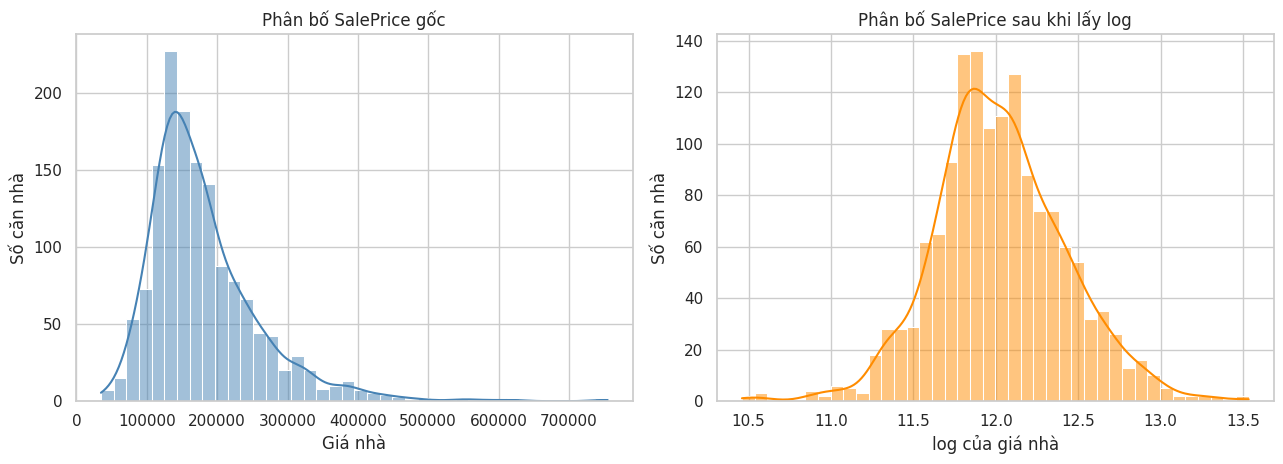

In [76]:
# Vẽ histogram giá nhà gốc và giá nhà sau khi lấy log
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

sns.histplot(y_train, bins=40, kde=True, color="steelblue", ax=axes[0])
axes[0].set_title("Phân bố SalePrice gốc")
axes[0].set_xlabel("Giá nhà")
axes[0].set_ylabel("Số căn nhà")

sns.histplot(np.log1p(y_train), bins=40, kde=True, color="darkorange", ax=axes[1])
axes[1].set_title("Phân bố SalePrice sau khi lấy log")
axes[1].set_xlabel("log của giá nhà")
axes[1].set_ylabel("Số căn nhà")

fig.tight_layout()
luu(fig, "01_phan_bo_gia_nha")

### 3.2. Tỷ lệ giá trị thiếu trước khi điền

In [77]:
# Lấy 15 cột thiếu nhiều nhất từ bảng missing_df đã tính trước khi điền
thieu = missing_df.head(15)['Tỷ lệ phần trăm (%)']
print(thieu.round(2))

PoolQC          99.52
MiscFeature     96.30
Alley           93.77
Fence           80.75
MasVnrType      59.73
FireplaceQu     47.26
LotFrontage     17.74
GarageType       5.55
GarageYrBlt      5.55
GarageFinish     5.55
GarageQual       5.55
GarageCond       5.55
BsmtExposure     2.60
BsmtFinType2     2.60
BsmtQual         2.53
Name: Tỷ lệ phần trăm (%), dtype: float64


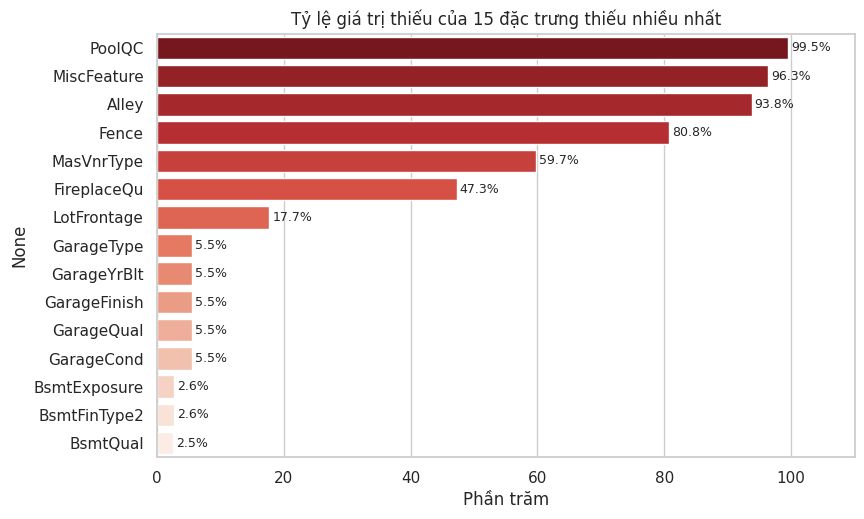

In [78]:
# Vẽ biểu đồ cột ngang tỷ lệ thiếu
fig, ax = plt.subplots(figsize=(9, 5.5))
sns.barplot(x=thieu.values, y=thieu.index, palette="Reds_r", ax=ax)

# Ghi phần trăm cạnh mỗi cột
for i, v in enumerate(thieu.values):
    ax.text(v + 0.5, i, f"{v:.1f}%", va="center", fontsize=9)

ax.set_title("Tỷ lệ giá trị thiếu của 15 đặc trưng thiếu nhiều nhất")
ax.set_xlabel("Phần trăm")
ax.set_xlim(0, 110)
luu(fig, "02_ty_le_thieu")

### 3.3. Tương quan giữa các đặc trưng số và giá nhà

In [79]:
# Tính hệ số tương quan của từng cột số với SalePrice
cot_so = train_hp.select_dtypes(include=[np.number])
tuong_quan = cot_so.corr()['SalePrice'].drop(['SalePrice', 'Id'])

# Lấy 15 đặc trưng có tương quan tuyệt đối lớn nhất
top15 = tuong_quan.reindex(tuong_quan.abs().sort_values(ascending=False).index).head(15)
print(top15.round(3))

OverallQual     0.791
GrLivArea       0.709
GarageCars      0.640
GarageArea      0.623
TotalBsmtSF     0.614
1stFlrSF        0.606
FullBath        0.561
TotRmsAbvGrd    0.534
YearBuilt       0.523
YearRemodAdd    0.507
MasVnrArea      0.473
Fireplaces      0.467
BsmtFinSF1      0.386
LotFrontage     0.335
WoodDeckSF      0.324
Name: SalePrice, dtype: float64


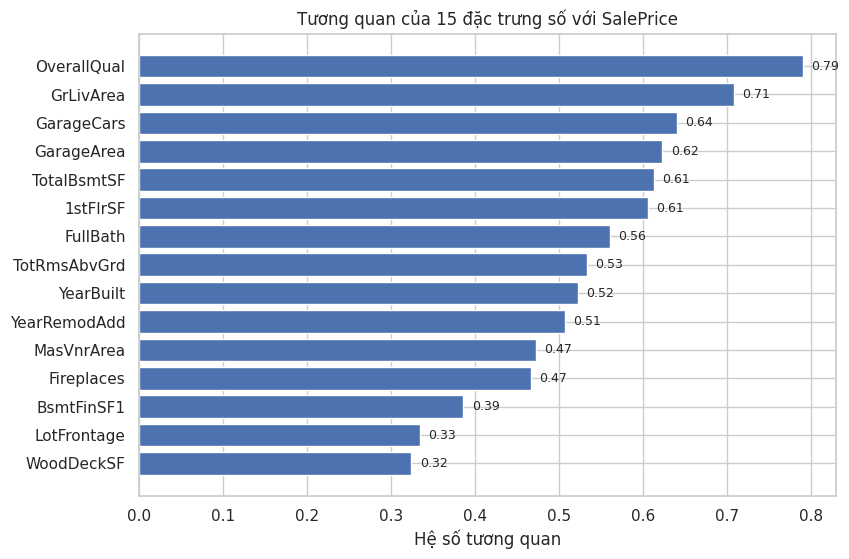

In [80]:
# Vẽ biểu đồ cột ngang hệ số tương quan
fig, ax = plt.subplots(figsize=(9, 6))
top15_sx = top15.sort_values()
mau = ["#C44E52" if v < 0 else "#4C72B0" for v in top15_sx.values]
ax.barh(top15_sx.index, top15_sx.values, color=mau)

# Ghi giá trị cạnh mỗi cột
for i, v in enumerate(top15_sx.values):
    ax.text(v + (0.01 if v >= 0 else -0.01), i, f"{v:.2f}",
            va="center", ha="left" if v >= 0 else "right", fontsize=9)

ax.set_title("Tương quan của 15 đặc trưng số với SalePrice")
ax.set_xlabel("Hệ số tương quan")
luu(fig, "03_tuong_quan_voi_gia")

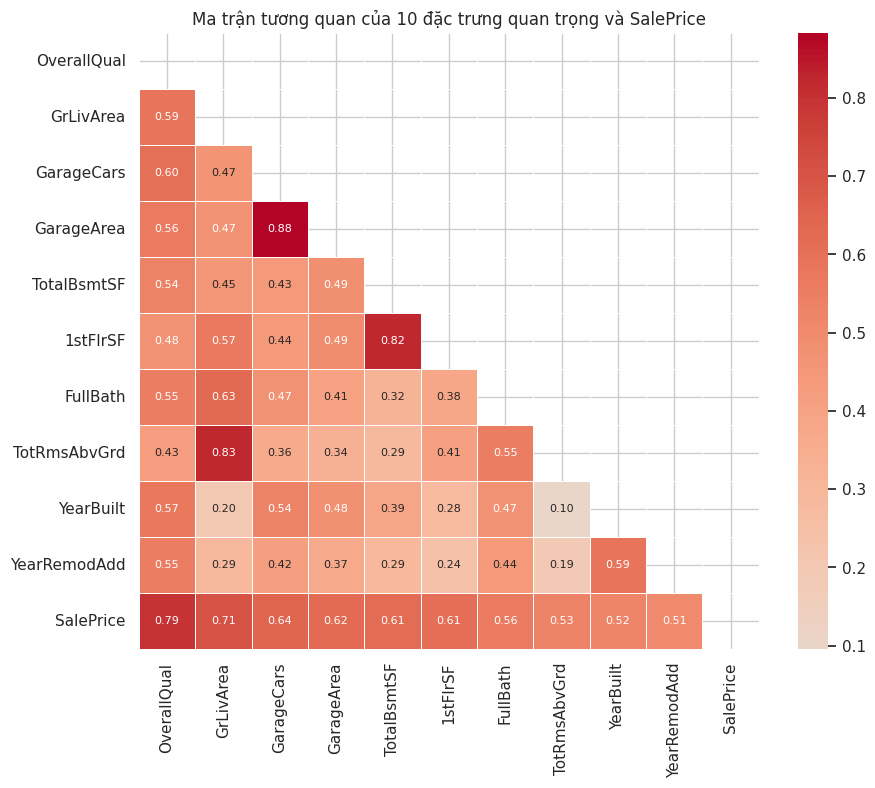

In [81]:
# Vẽ heatmap tương quan cho 10 đặc trưng liên quan nhất và SalePrice
top10 = top15.index[:10].tolist()
corr10 = cot_so[top10 + ['SalePrice']].corr()
mask = np.triu(np.ones_like(corr10, dtype=bool))

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr10, mask=mask, annot=True, fmt=".2f", cmap="coolwarm",
            center=0, linewidths=0.5, annot_kws={"size": 8}, ax=ax)
ax.set_title("Ma trận tương quan của 10 đặc trưng quan trọng và SalePrice")
luu(fig, "04_heatmap_tuong_quan")

### 3.4. Các đặc trưng liên quan nhất so với giá nhà

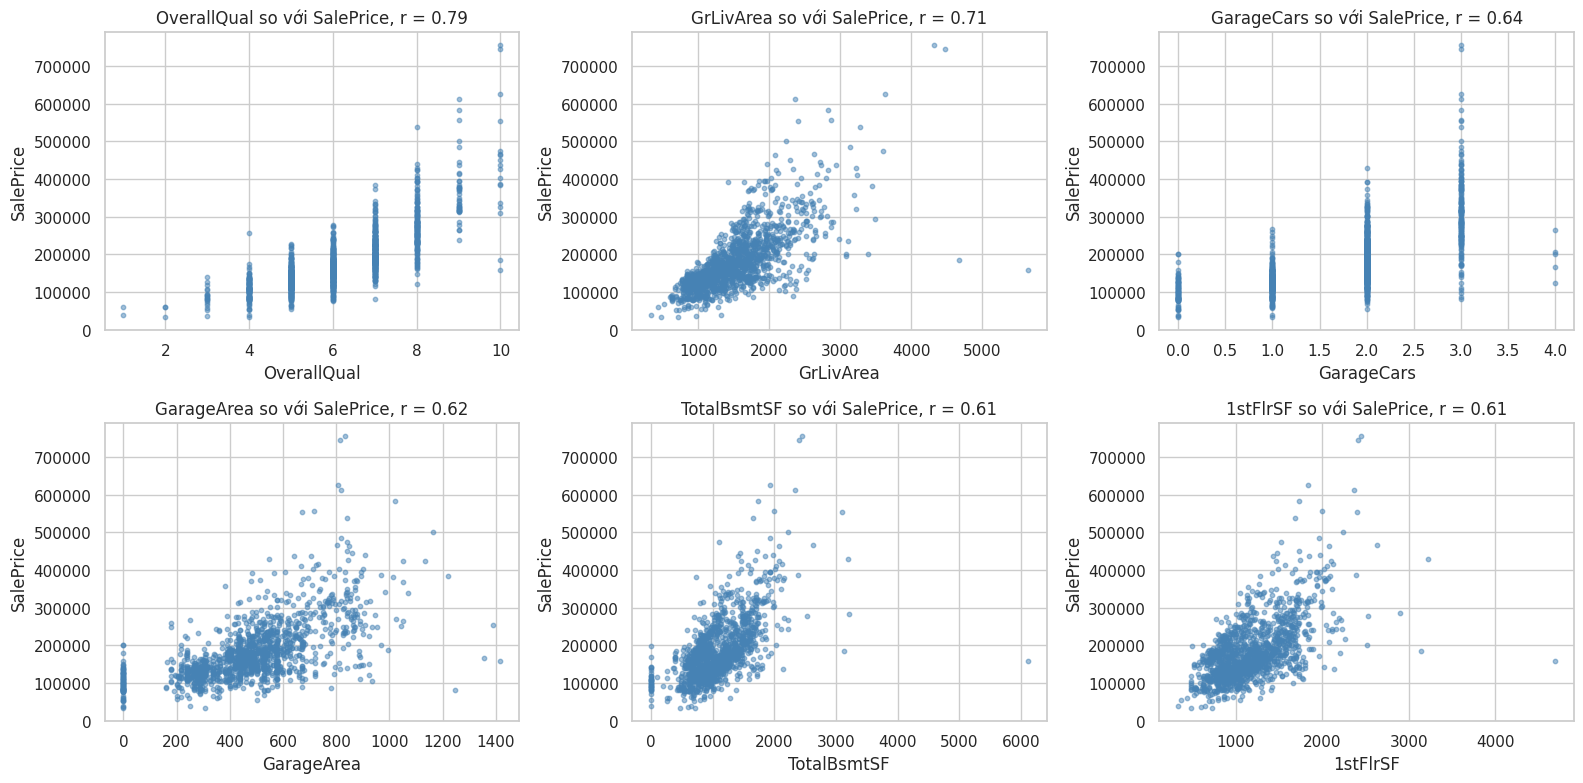

In [82]:
# Vẽ biểu đồ phân tán của 6 đặc trưng liên quan nhất so với giá nhà
top6 = top15.index[:6].tolist()

fig, axes = plt.subplots(2, 3, figsize=(16, 8))

for ax, c in zip(axes.ravel(), top6):
    ax.scatter(train_hp[c], train_hp['SalePrice'], s=10, alpha=0.5, color="steelblue")
    ax.set_title(f"{c} so với SalePrice, r = {tuong_quan[c]:.2f}")
    ax.set_xlabel(c)
    ax.set_ylabel("SalePrice")

fig.tight_layout()
luu(fig, "05_dac_trung_vs_gia")

### 3.5. Huấn luyện lại các mô hình chỉ trên 80% dữ liệu

In [83]:
# Gom các mô hình đã tạo ở Phần 2 vào một dict
goc = {
    "Ridge": model_ridge,
    "Random Forest": model_rf,
    "Decision Tree": model_dt,
    "Extra Trees": model_et,
    "Gradient Boosting": model_gb,
    "AdaBoost": model_ab,
    "KNN": model_knn,
    "SVR": model_svr,
    "MLP": model_mlp,
}

In [84]:
# Dict lưu kết quả của từng mô hình
KQ = {}

for ten, m in goc.items():
    # Clone để có mô hình mới cùng tham số, chưa huấn luyện
    mo = clone(m)

    # Đo thời gian huấn luyện
    t0 = time.time()
    mo.fit(X_tr, y_tr)
    thoi_gian = time.time() - t0

    # Dự đoán trên tập validation và tập train
    pred_val = mo.predict(X_val)
    pred_tr = mo.predict(X_tr)

    # Lưu kết quả
    KQ[ten] = {
        "model": mo,
        "pred": pred_val,
        "pred_tr": pred_tr,
        "rmse_val": rmse(y_val, pred_val),
        "rmse_train": rmse(y_tr, pred_tr),
        "mae_val": float(mean_absolute_error(y_val, pred_val)),
        "r2_val": float(r2_score(y_val, pred_val)),
        "rmsle_val": rmsle(y_val, pred_val),
        "time": thoi_gian,
    }

    print(f"{ten:18s} | RMSE Val = {KQ[ten]['rmse_val']:10.2f} | "
          f"RMSE Train = {KQ[ten]['rmse_train']:10.2f} | Thời gian = {thoi_gian:.2f}s")

Ridge              | RMSE Val =   29737.23 | RMSE Train =   21200.18 | Thời gian = 0.14s
Random Forest      | RMSE Val =   28713.83 | RMSE Train =   11027.84 | Thời gian = 4.27s
Decision Tree      | RMSE Val =   43357.99 | RMSE Train =       0.00 | Thời gian = 0.07s
Extra Trees        | RMSE Val =   28205.18 | RMSE Train =       0.00 | Thời gian = 4.24s
Gradient Boosting  | RMSE Val =   27819.87 | RMSE Train =   13299.21 | Thời gian = 1.36s
AdaBoost           | RMSE Val =   36134.01 | RMSE Train =   27949.19 | Thời gian = 0.68s
KNN                | RMSE Val =   47943.56 | RMSE Train =   37663.19 | Thời gian = 0.01s
SVR                | RMSE Val =   88667.17 | RMSE Train =   78961.23 | Thời gian = 0.22s
MLP                | RMSE Val =   38795.69 | RMSE Train =   31033.68 | Thời gian = 10.15s


In [85]:
# Sắp xếp mô hình theo RMSE validation tăng dần, sai số nhỏ nhất là tốt nhất
thu_tu = sorted(KQ, key=lambda k: KQ[k]["rmse_val"])
ten_tot_nhat = thu_tu[0]

print("Thứ tự các mô hình:", thu_tu)
print("Mô hình tốt nhất:", ten_tot_nhat)

Thứ tự các mô hình: ['Gradient Boosting', 'Extra Trees', 'Random Forest', 'Ridge', 'AdaBoost', 'MLP', 'Decision Tree', 'KNN', 'SVR']
Mô hình tốt nhất: Gradient Boosting


### 3.6. So sánh RMSE giữa các mô hình

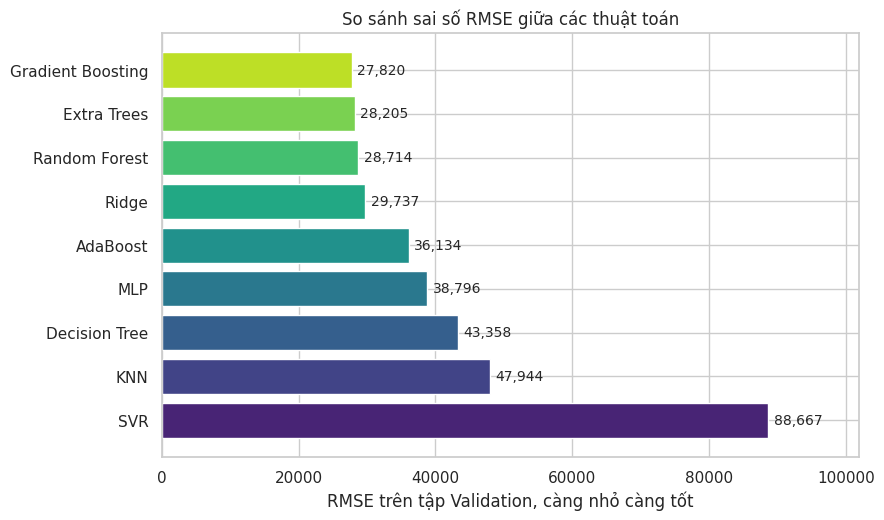

In [86]:
# Vẽ biểu đồ cột ngang so sánh RMSE
vals = [KQ[k]["rmse_val"] for k in thu_tu]

fig, ax = plt.subplots(figsize=(9, 5.5))
bars = ax.barh(thu_tu[::-1], vals[::-1],
               color=sns.color_palette("viridis", len(thu_tu)))

# Ghi giá trị cạnh mỗi cột
for b in bars:
    ax.text(b.get_width() + 800, b.get_y() + b.get_height() / 2,
            f"{b.get_width():,.0f}", va="center", fontsize=10)

ax.set_xlim(0, max(vals) * 1.15)
ax.set_xlabel("RMSE trên tập Validation, càng nhỏ càng tốt")
ax.set_title("So sánh sai số RMSE giữa các thuật toán")
luu(fig, "06_so_sanh_rmse")

### 3.7. So sánh RMSE, MAE, R2 và RMSLE

In [87]:
# Gom các chỉ số của từng mô hình vào một bảng
rows = []
for k in thu_tu:
    rows.append({
        "Mô hình": k,
        "RMSE": KQ[k]["rmse_val"],
        "MAE": KQ[k]["mae_val"],
        "R2": KQ[k]["r2_val"],
        "RMSLE": KQ[k]["rmsle_val"],
    })

df_metric = pd.DataFrame(rows).set_index("Mô hình")
df_metric = df_metric.round(4)
print(df_metric)

# Lưu bảng ra file csv để chèn vào báo cáo
df_metric.to_csv(f"{THU_MUC}/bang_so_sanh_chi_so.csv")

                         RMSE         MAE      R2   RMSLE
Mô hình                                                  
Gradient Boosting  27819.8655  17161.5573  0.8991  0.1410
Extra Trees        28205.1827  17798.3496  0.8963  0.1564
Random Forest      28713.8284  17618.5511  0.8925  0.1547
Ridge              29737.2316  19125.7429  0.8847  0.1653
AdaBoost           36134.0073  25836.0339  0.8298  0.2255
MLP                38795.6893  23462.8502  0.8038  0.2486
Decision Tree      43357.9876  27963.7021  0.7549  0.2261
KNN                47943.5569  28541.5596  0.7003  0.2289
SVR                88667.1712  59568.2273 -0.0250  0.4323


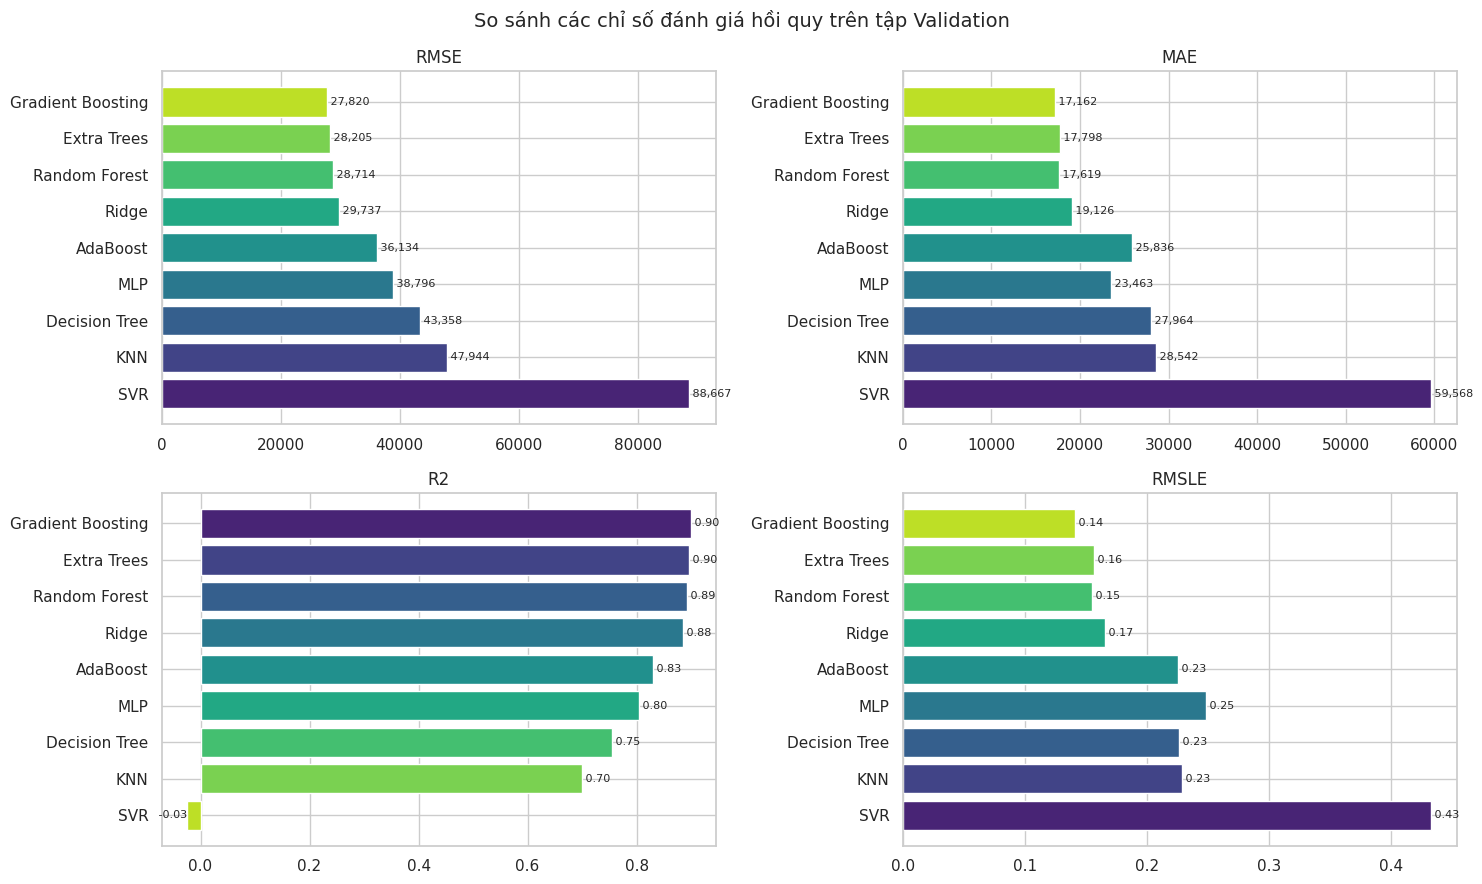

In [88]:
# Vẽ 4 biểu đồ cột ngang, mỗi biểu đồ là một chỉ số
fig, axes = plt.subplots(2, 2, figsize=(15, 9))
chi_so = [("RMSE", "viridis"), ("MAE", "viridis"), ("R2", "viridis_r"), ("RMSLE", "viridis")]

for ax, (c, bang_mau) in zip(axes.ravel(), chi_so):
    gia_tri = df_metric[c].values
    bars = ax.barh(thu_tu[::-1], gia_tri[::-1],
                   color=sns.color_palette(bang_mau, len(thu_tu)))
    for b in bars:
        w = b.get_width()
        ax.text(w, b.get_y() + b.get_height() / 2, f" {w:,.2f}" if c in ("R2", "RMSLE") else f" {w:,.0f}",
                va="center", ha="left" if w >= 0 else "right", fontsize=8)
    ax.set_title(c)

fig.suptitle("So sánh các chỉ số đánh giá hồi quy trên tập Validation", fontsize=14)
fig.tight_layout()
luu(fig, "07_so_sanh_chi_so")

### 3.8. Giá dự đoán so với giá thật

In [89]:
# Chọn khoảng trục chung cho mọi hình
gioi_han = [0, float(y_val.max()) * 1.05]

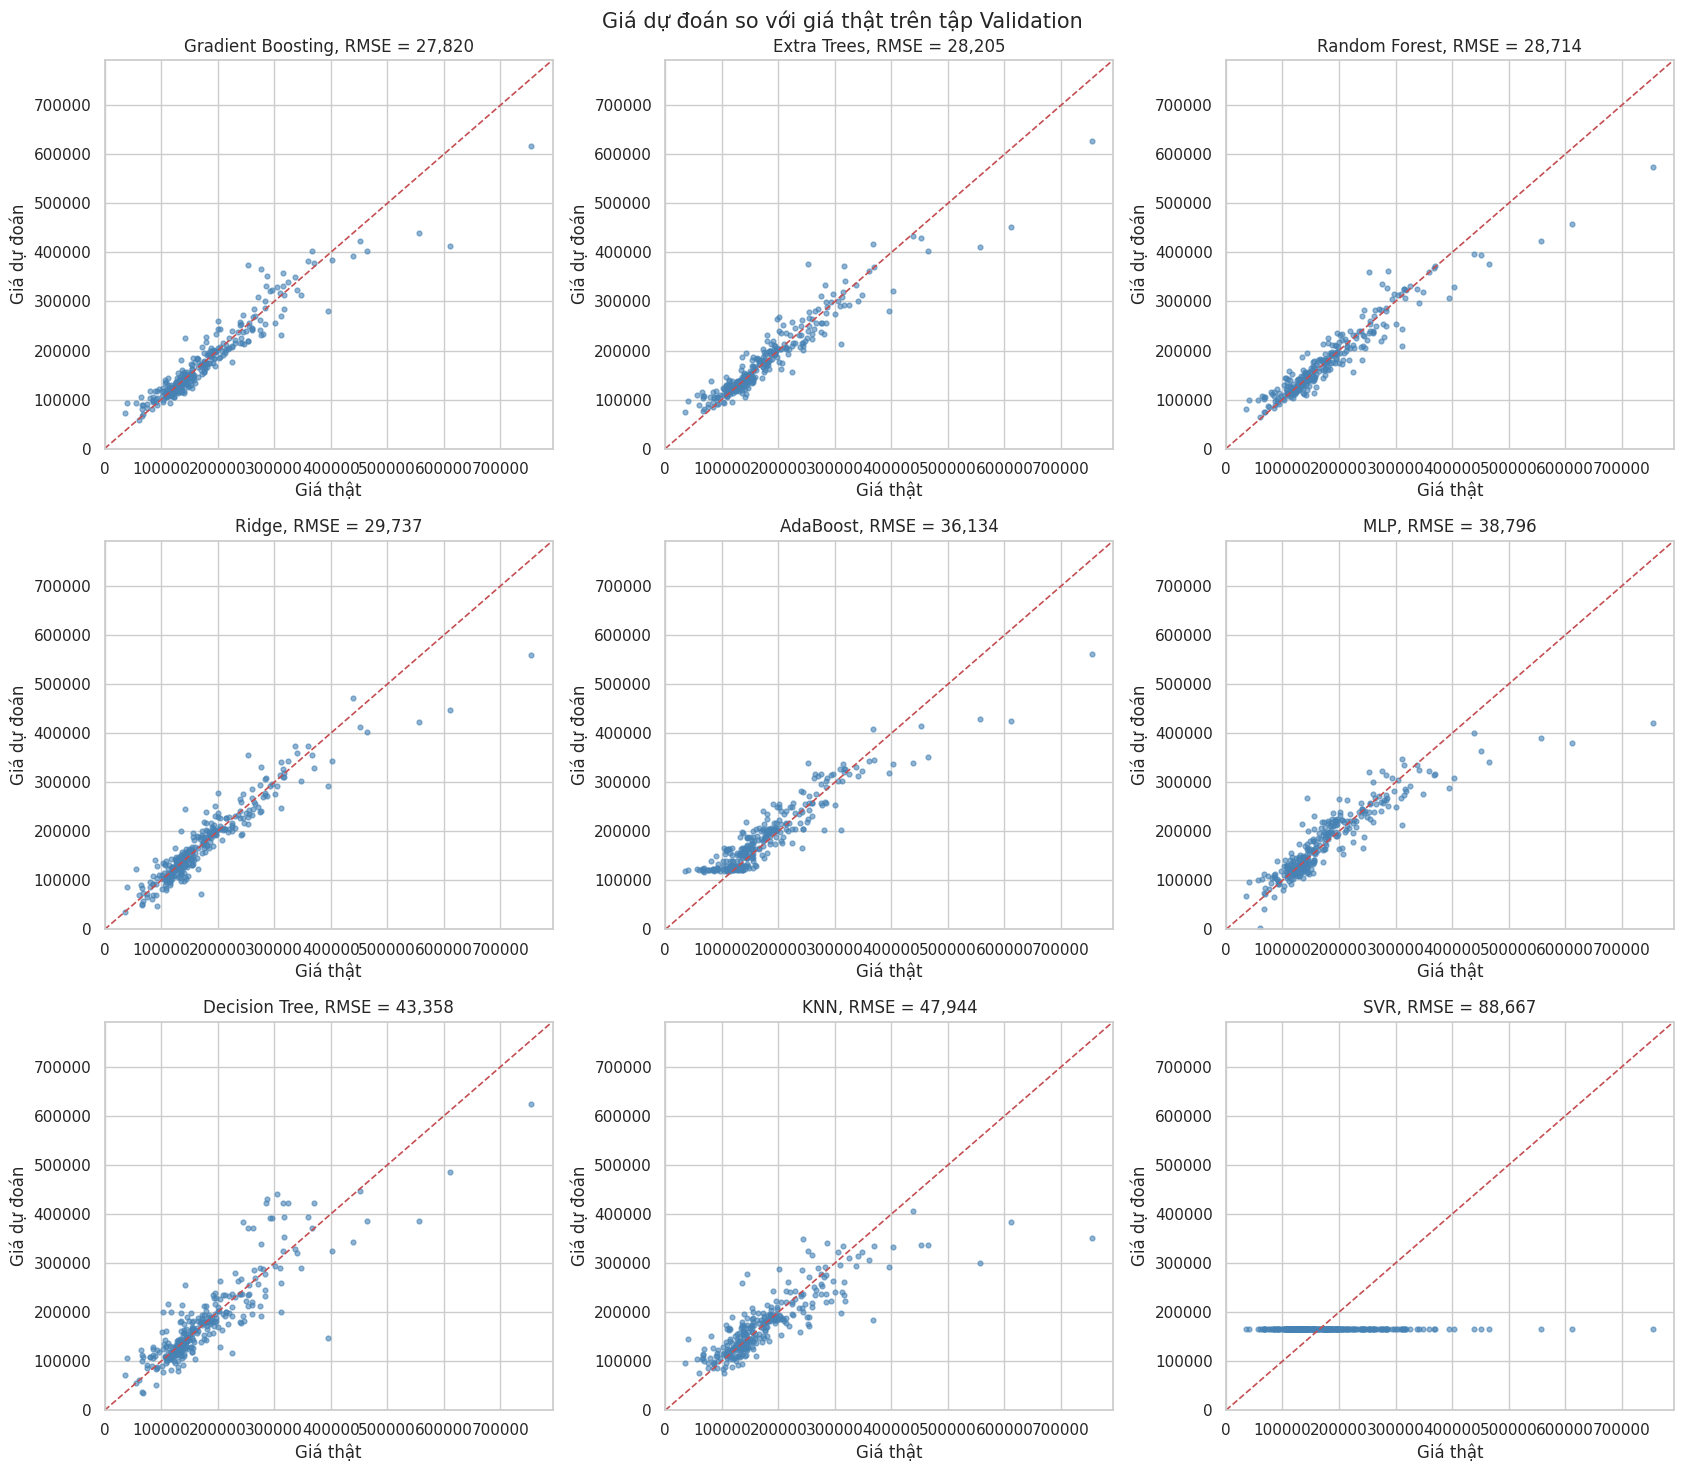

In [90]:
# Vẽ giá dự đoán so với giá thật cho cả 9 mô hình
fig, axes = plt.subplots(3, 3, figsize=(17, 15))

for ax, k in zip(axes.ravel(), thu_tu):
    ax.scatter(y_val, KQ[k]["pred"], s=12, alpha=0.6, color="steelblue")
    ax.plot(gioi_han, gioi_han, "r--", lw=1.2, label="Dự đoán hoàn hảo")
    ax.set_xlim(gioi_han)
    ax.set_ylim(gioi_han)
    ax.set_title(f"{k}, RMSE = {KQ[k]['rmse_val']:,.0f}")
    ax.set_xlabel("Giá thật")
    ax.set_ylabel("Giá dự đoán")

fig.suptitle("Giá dự đoán so với giá thật trên tập Validation", fontsize=15)
fig.tight_layout()
luu(fig, "08_du_doan_vs_thuc_te")

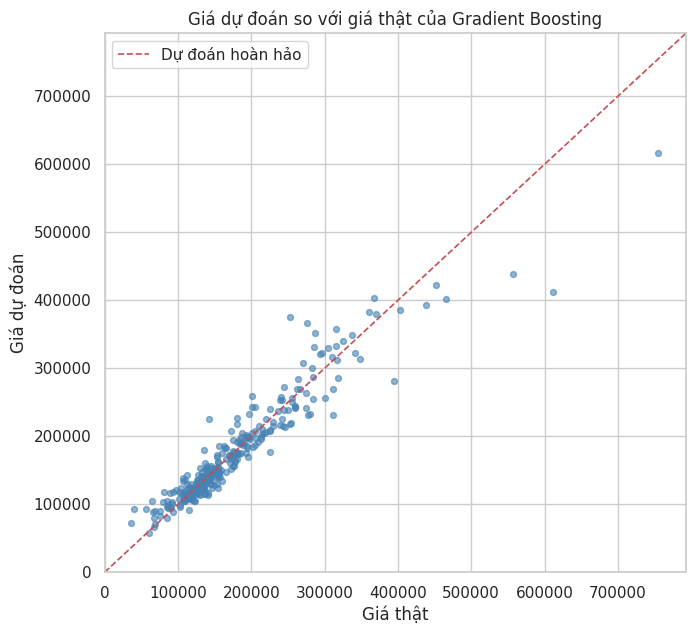

In [91]:
# Vẽ riêng cho mô hình tốt nhất
fig, ax = plt.subplots(figsize=(7.5, 7))
ax.scatter(y_val, KQ[ten_tot_nhat]["pred"], s=18, alpha=0.6, color="steelblue")
ax.plot(gioi_han, gioi_han, "r--", lw=1.2, label="Dự đoán hoàn hảo")
ax.set_xlim(gioi_han)
ax.set_ylim(gioi_han)
ax.set_xlabel("Giá thật")
ax.set_ylabel("Giá dự đoán")
ax.set_title(f"Giá dự đoán so với giá thật của {ten_tot_nhat}")
ax.legend()
luu(fig, "08b_du_doan_vs_thuc_te_tot_nhat")

### 3.9. Phần dư của các mô hình

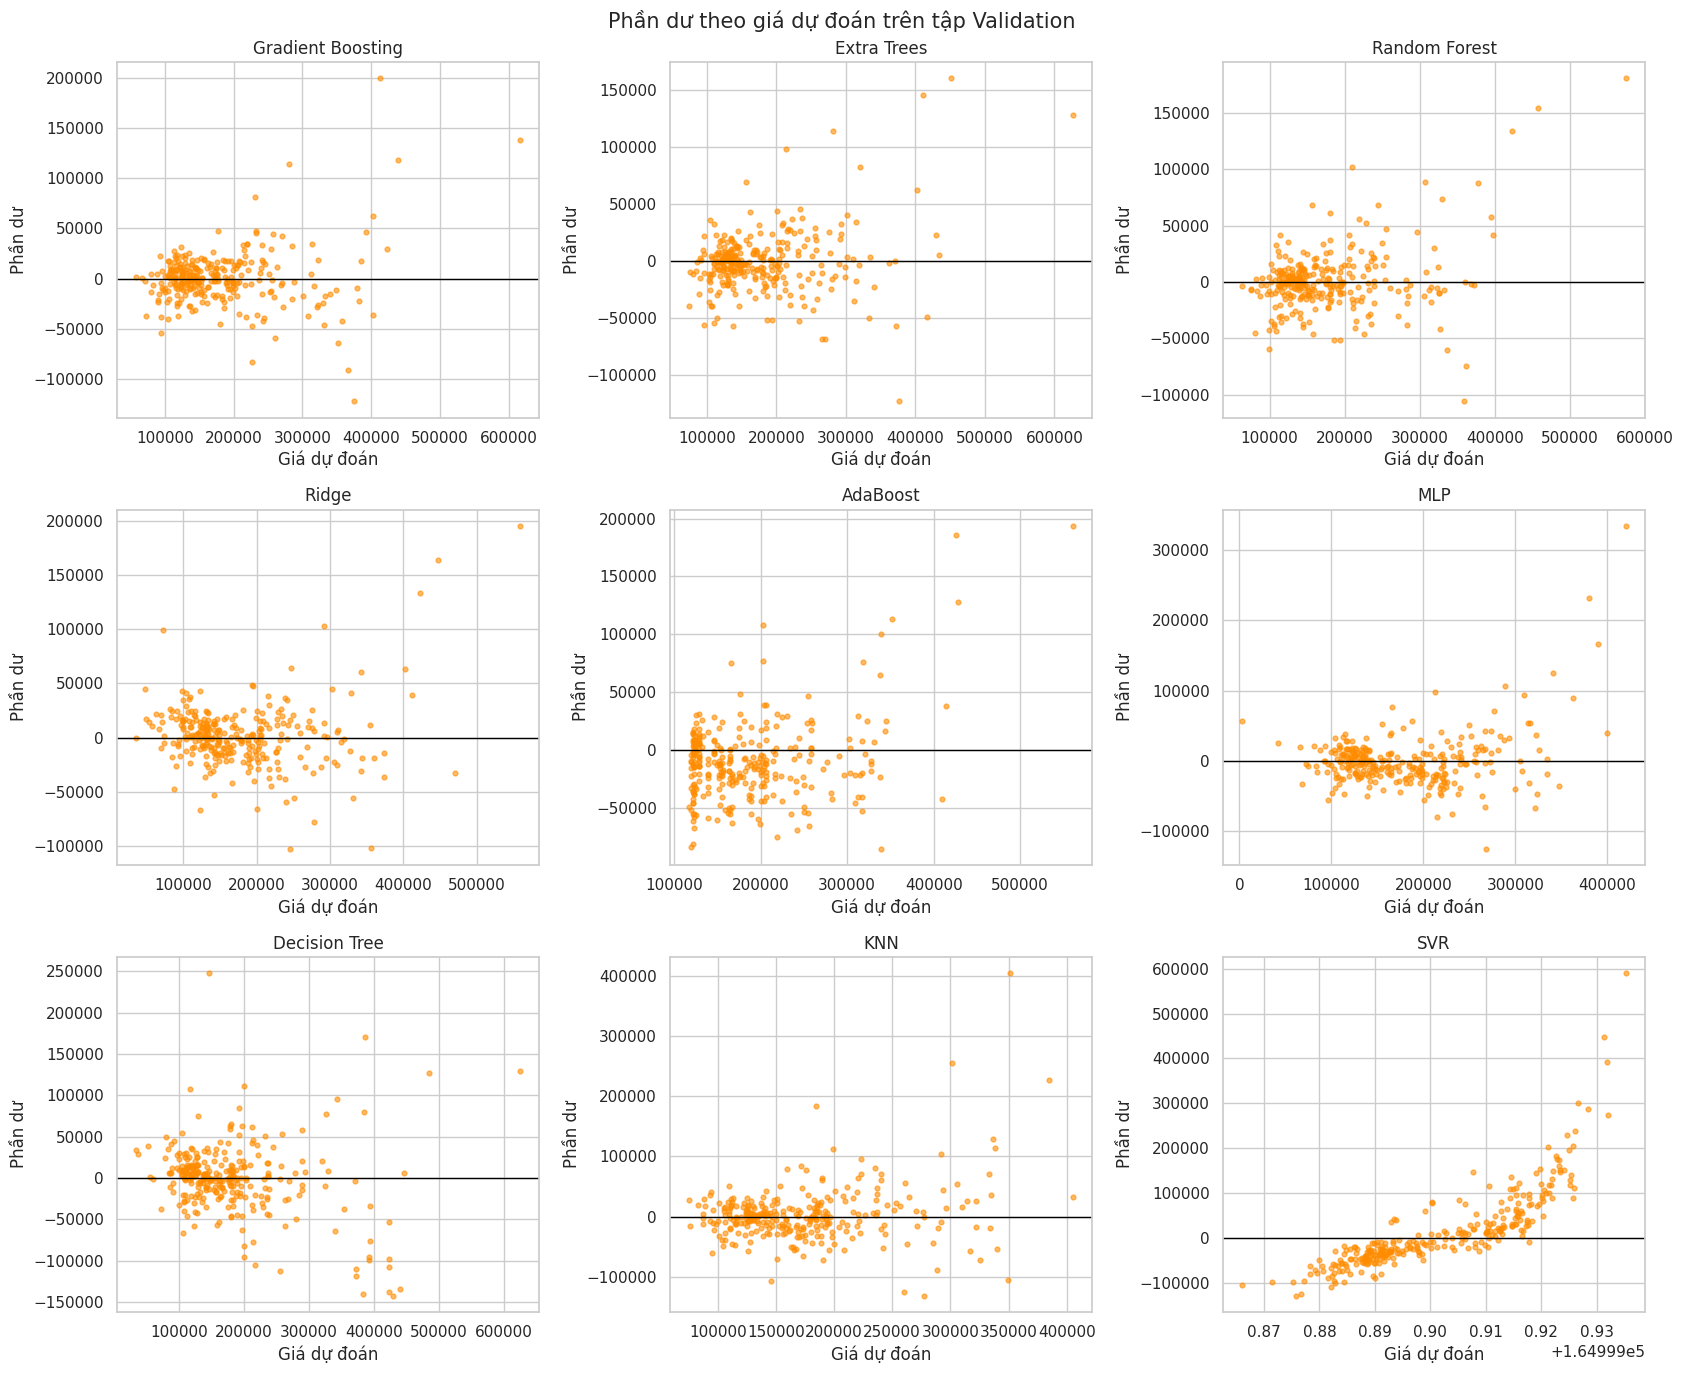

In [92]:
# Phần dư bằng giá thật trừ giá dự đoán, vẽ theo giá dự đoán cho cả 9 mô hình
fig, axes = plt.subplots(3, 3, figsize=(17, 14))

for ax, k in zip(axes.ravel(), thu_tu):
    phan_du = y_val.values - KQ[k]["pred"]
    ax.scatter(KQ[k]["pred"], phan_du, s=12, alpha=0.6, color="darkorange")
    ax.axhline(0, color="black", lw=1)
    ax.set_title(k)
    ax.set_xlabel("Giá dự đoán")
    ax.set_ylabel("Phần dư")

fig.suptitle("Phần dư theo giá dự đoán trên tập Validation", fontsize=15)
fig.tight_layout()
luu(fig, "09_phan_du")

In [93]:
# Gom sai số tuyệt đối của từng mô hình vào một bảng
sai_so = pd.DataFrame({k: np.abs(y_val.values - KQ[k]["pred"]) for k in thu_tu})
print(sai_so.median().round(0))

Gradient Boosting    11197.0
Extra Trees          10806.0
Random Forest        10619.0
Ridge                13539.0
AdaBoost             19618.0
MLP                  16112.0
Decision Tree        16322.0
KNN                  17831.0
SVR                  40000.0
dtype: float64


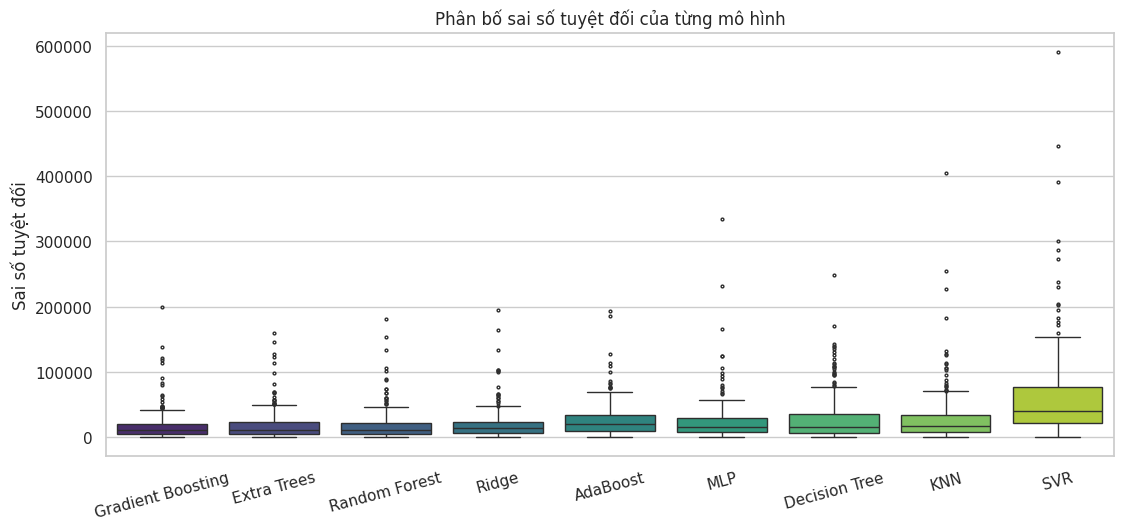

In [94]:
# Vẽ boxplot sai số tuyệt đối của từng mô hình
fig, ax = plt.subplots(figsize=(13, 5.5))
sns.boxplot(data=sai_so, palette="viridis", fliersize=2, ax=ax)
ax.set_ylabel("Sai số tuyệt đối")
ax.set_title("Phân bố sai số tuyệt đối của từng mô hình")
plt.xticks(rotation=15)
luu(fig, "09b_sai_so_tuyet_doi")

### 3.10. So sánh Train và Validation để xem overfitting

In [95]:
# Lấy RMSE train và validation của từng mô hình
tr = [KQ[k]["rmse_train"] for k in thu_tu]
va = [KQ[k]["rmse_val"] for k in thu_tu]

x = np.arange(len(thu_tu))
w = 0.38

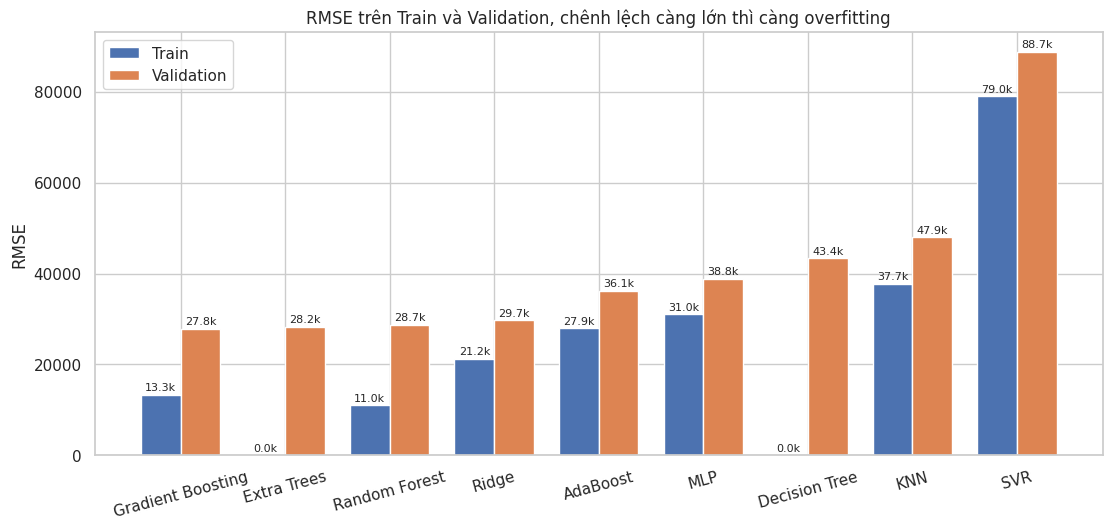

In [96]:
# Vẽ cột đôi Train và Validation
fig, ax = plt.subplots(figsize=(13, 5.5))
b1 = ax.bar(x - w / 2, tr, w, label="Train", color="#4C72B0")
b2 = ax.bar(x + w / 2, va, w, label="Validation", color="#DD8452")

# Ghi giá trị lên đầu cột
for b in list(b1) + list(b2):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 1000,
            f"{b.get_height() / 1000:.1f}k", ha="center", fontsize=8)

ax.set_xticks(x)
ax.set_xticklabels(thu_tu, rotation=15)
ax.set_ylabel("RMSE")
ax.set_title("RMSE trên Train và Validation, chênh lệch càng lớn thì càng overfitting")
ax.legend()
luu(fig, "10_train_vs_val")

### 3.11. Thời gian huấn luyện

In [97]:
# Lấy thời gian huấn luyện rồi sắp xếp tăng dần
tg = pd.Series({k: KQ[k]["time"] for k in KQ}).sort_values()
print(tg.round(2))

KNN                   0.01
Decision Tree         0.07
Ridge                 0.14
SVR                   0.22
AdaBoost              0.68
Gradient Boosting     1.36
Extra Trees           4.24
Random Forest         4.27
MLP                  10.15
dtype: float64


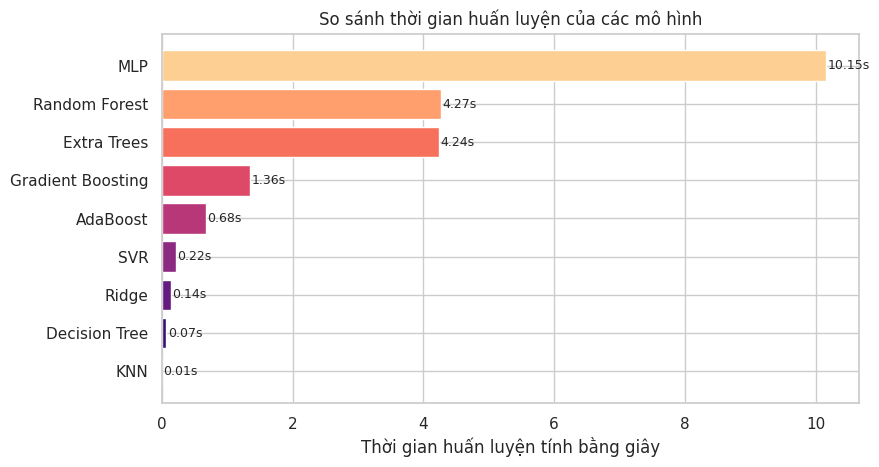

In [98]:
# Vẽ biểu đồ cột ngang thời gian huấn luyện
fig, ax = plt.subplots(figsize=(9, 4.8))
bars = ax.barh(tg.index, tg.values, color=sns.color_palette("magma", len(tg)))

for b in bars:
    ax.text(b.get_width() + 0.02, b.get_y() + b.get_height() / 2,
            f"{b.get_width():.2f}s", va="center", fontsize=9)

ax.set_xlabel("Thời gian huấn luyện tính bằng giây")
ax.set_title("So sánh thời gian huấn luyện của các mô hình")
luu(fig, "11_thoi_gian_huan_luyen")

### 3.12. Độ quan trọng của đặc trưng

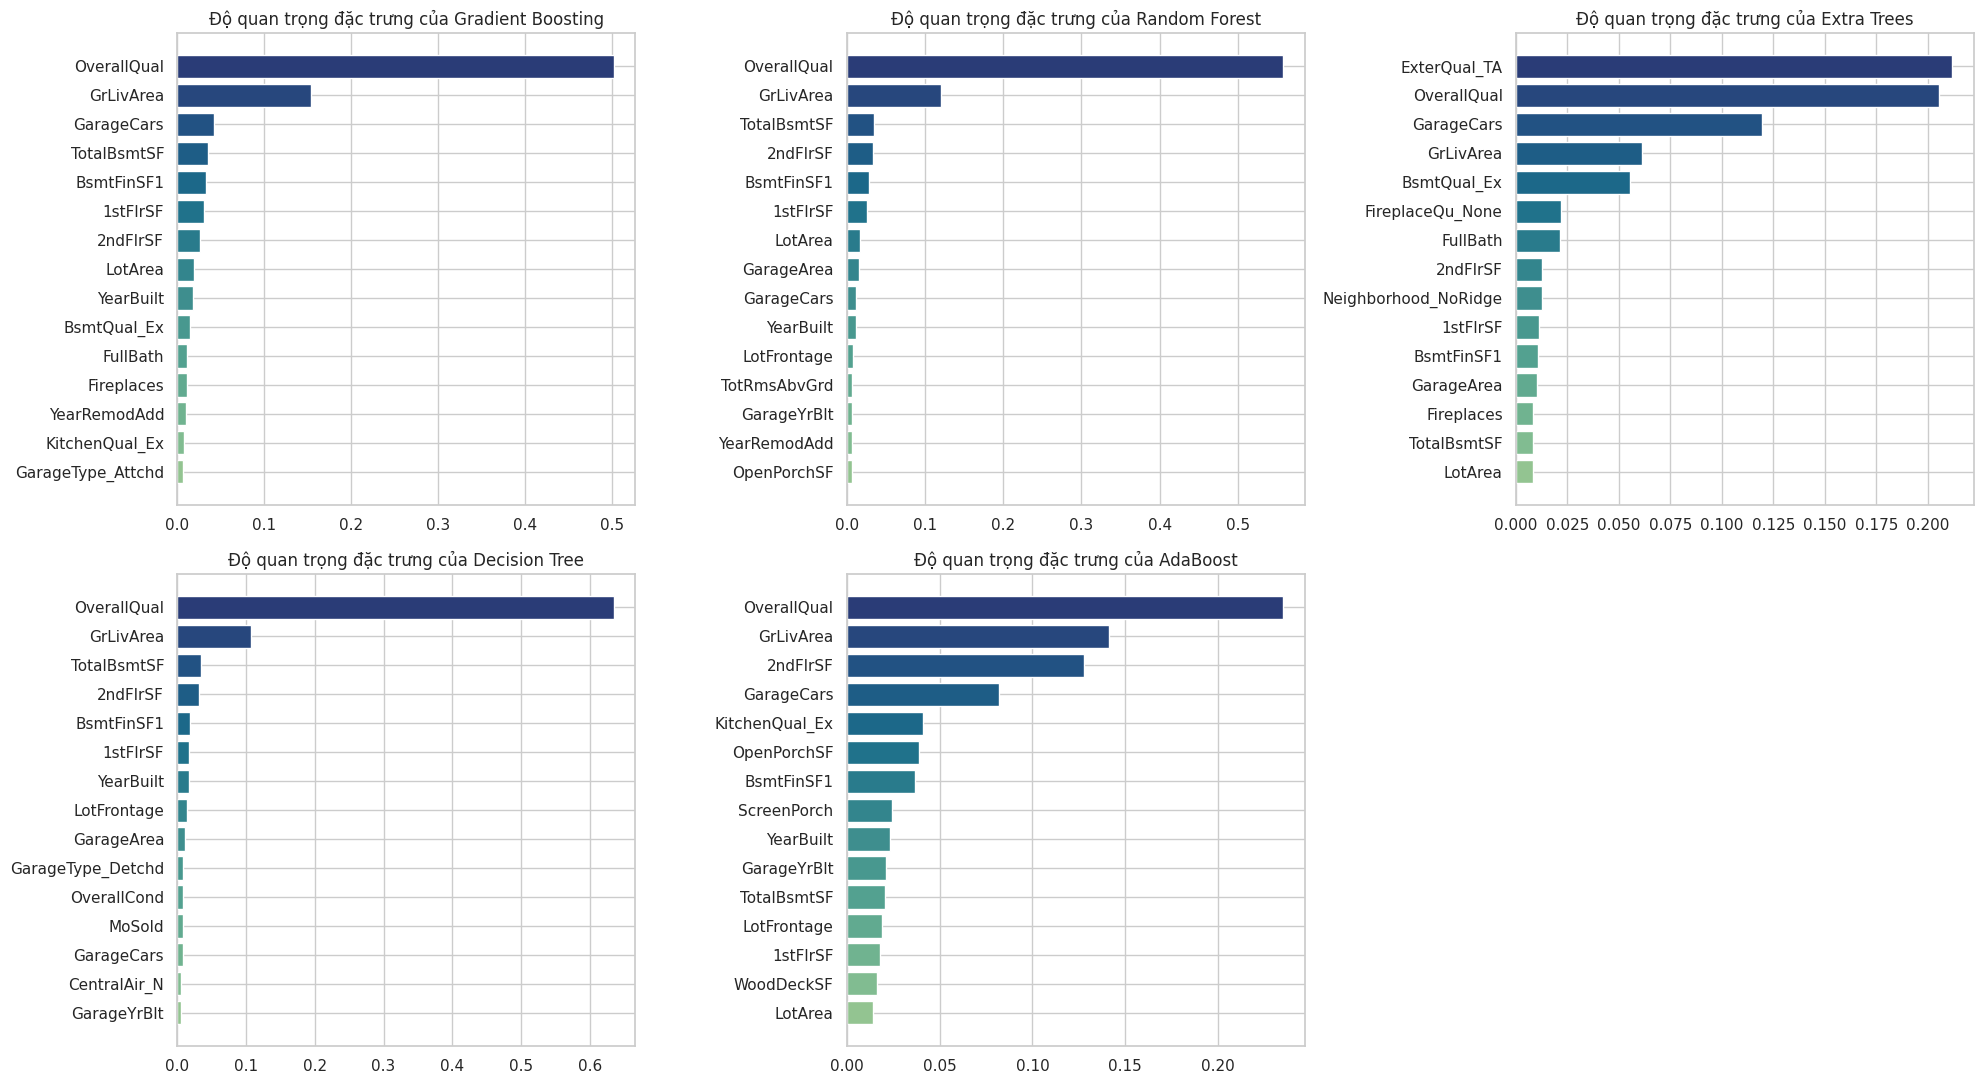

In [99]:
# Chỉ các mô hình dựa trên cây mới có feature_importances_
cay = ["Gradient Boosting", "Random Forest", "Extra Trees", "Decision Tree", "AdaBoost"]

fig, axes = plt.subplots(2, 3, figsize=(20, 11))

for ax, k in zip(axes.ravel(), cay):
    # Lấy 15 đặc trưng quan trọng nhất rồi sắp xếp tăng dần
    imp = pd.Series(KQ[k]["model"].feature_importances_,
                    index=feature_names).sort_values().tail(15)
    ax.barh(imp.index, imp.values, color=sns.color_palette("crest", len(imp)))
    ax.set_title(f"Độ quan trọng đặc trưng của {k}")

# Tắt ô thừa vì chỉ có 5 mô hình
for ax in axes.ravel()[len(cay):]:
    ax.axis("off")

fig.tight_layout()
luu(fig, "12_feature_importance")

### 3.13. Hình cây quyết định

In [100]:
# Cây gốc quá sâu nên không vẽ được, ta tạo cây phụ có độ sâu 3
dt3 = DecisionTreeRegressor(max_depth=3, random_state=42)
dt3.fit(X_tr, y_tr)

rmse_dt3 = rmse(y_val, dt3.predict(X_val))
print(f"RMSE của cây độ sâu 3: {rmse_dt3:.2f}")

RMSE của cây độ sâu 3: 41874.35


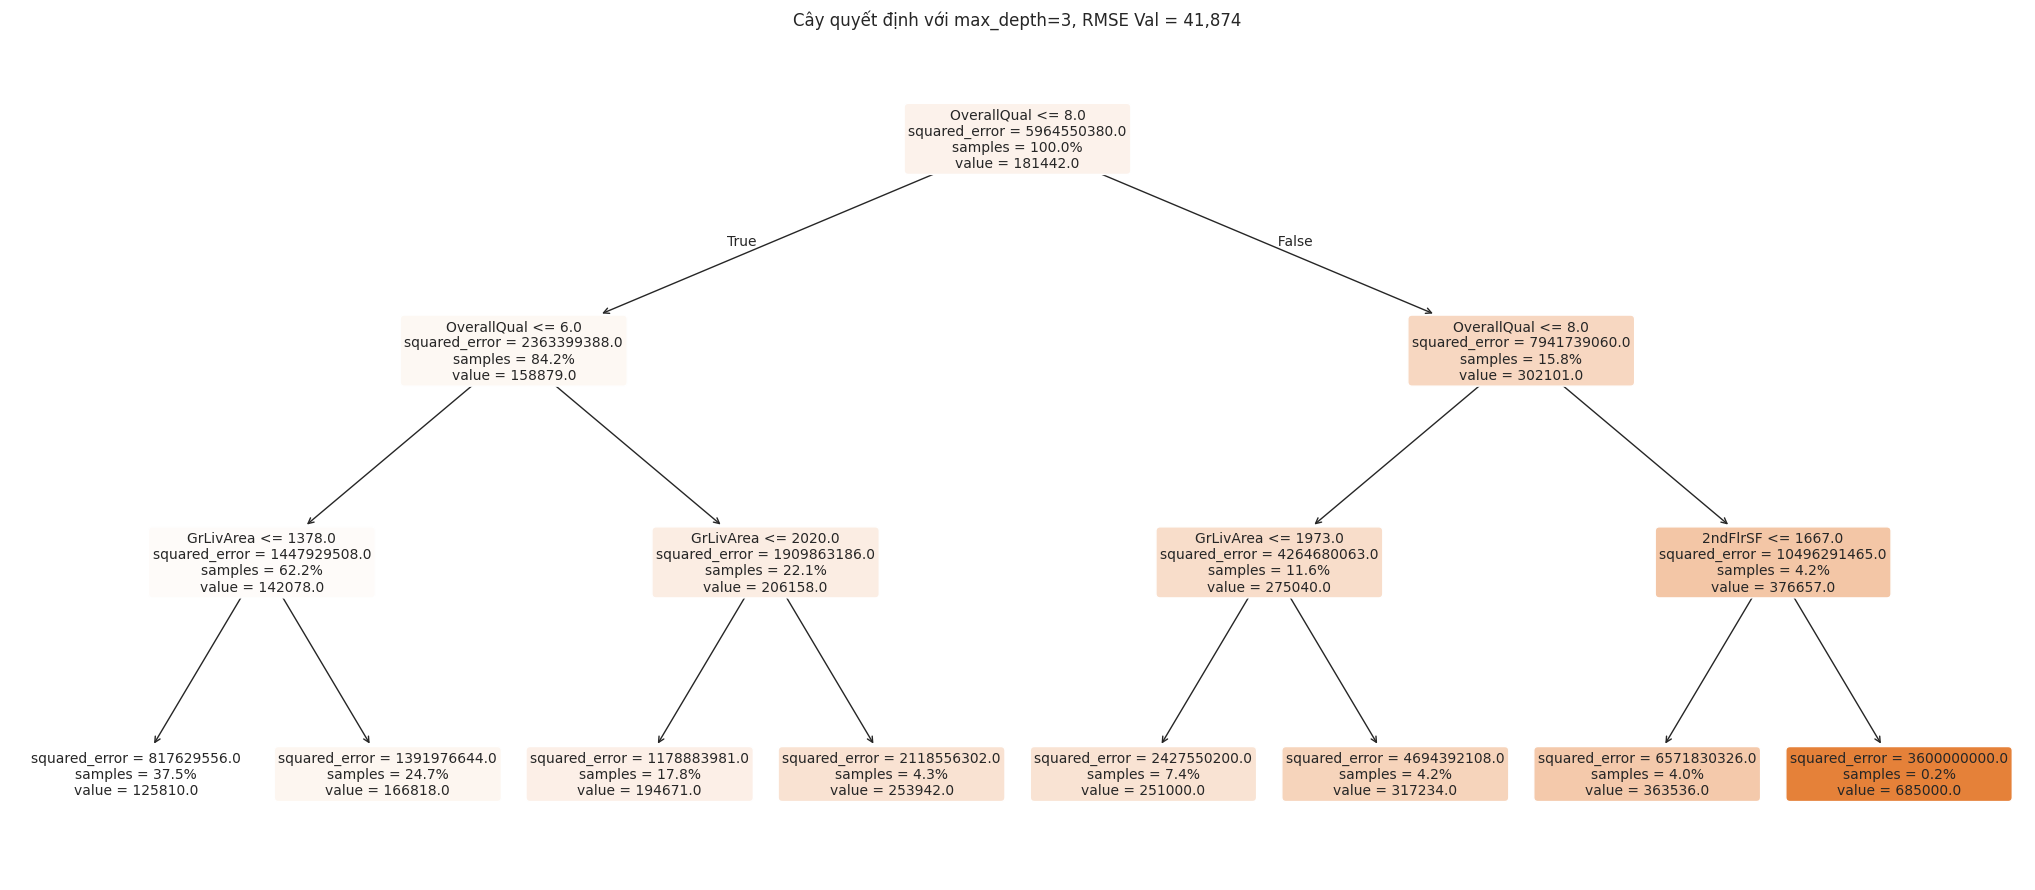

In [101]:
# Vẽ cây quyết định
fig, ax = plt.subplots(figsize=(26, 11))
plot_tree(dt3, feature_names=feature_names, filled=True, rounded=True,
          fontsize=10, proportion=True, precision=0, ax=ax)
ax.set_title(f"Cây quyết định với max_depth=3, RMSE Val = {rmse_dt3:,.0f}")
luu(fig, "13_decision_tree_depth3")

### 3.14. Decision Tree: ảnh hưởng của max_depth

In [102]:
# Thử độ sâu từ 1 đến 30, ghi lại RMSE train và validation
do_sau = list(range(1, 31))
e_tr = []
e_va = []

for d in do_sau:
    m = DecisionTreeRegressor(max_depth=d, random_state=42)
    m.fit(X_tr, y_tr)
    e_tr.append(rmse(y_tr, m.predict(X_tr)))
    e_va.append(rmse(y_val, m.predict(X_val)))

# Độ sâu cho RMSE validation nhỏ nhất
best_d = do_sau[int(np.argmin(e_va))]
print("max_depth tốt nhất:", best_d, "với RMSE =", round(min(e_va), 2))

max_depth tốt nhất: 6 với RMSE = 35831.9


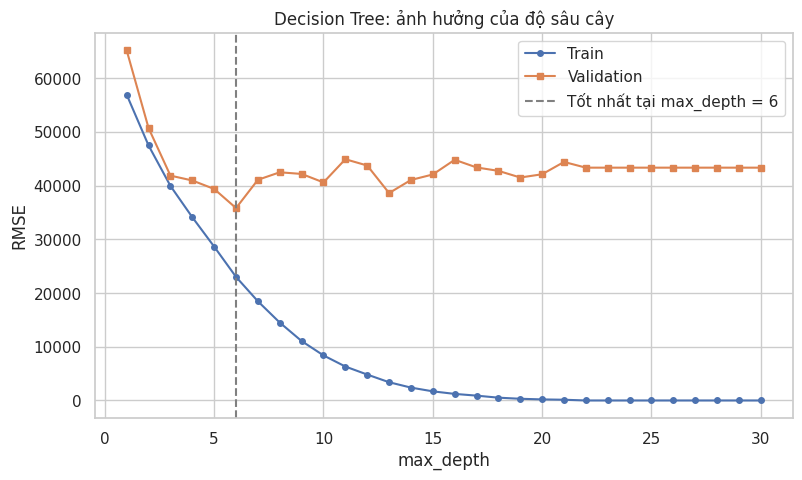

In [103]:
# Vẽ đường RMSE theo độ sâu
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(do_sau, e_tr, "o-", label="Train", ms=4)
ax.plot(do_sau, e_va, "s-", label="Validation", ms=4)
ax.axvline(best_d, ls="--", c="gray", label=f"Tốt nhất tại max_depth = {best_d}")
ax.set_xlabel("max_depth")
ax.set_ylabel("RMSE")
ax.set_title("Decision Tree: ảnh hưởng của độ sâu cây")
ax.legend()
luu(fig, "14_dt_max_depth")

### 3.15. Random Forest: ảnh hưởng của số cây

In [104]:
# Thử các số lượng cây khác nhau
n_list = [10, 25, 50, 100, 200, 300]
e_tr = []
e_va = []

for n in n_list:
    m = RandomForestRegressor(n_estimators=n, random_state=42, n_jobs=-1)
    m.fit(X_tr, y_tr)
    e_tr.append(rmse(y_tr, m.predict(X_tr)))
    e_va.append(rmse(y_val, m.predict(X_val)))
    print("Xong n_estimators =", n)

Xong n_estimators = 10
Xong n_estimators = 25
Xong n_estimators = 50
Xong n_estimators = 100
Xong n_estimators = 200
Xong n_estimators = 300


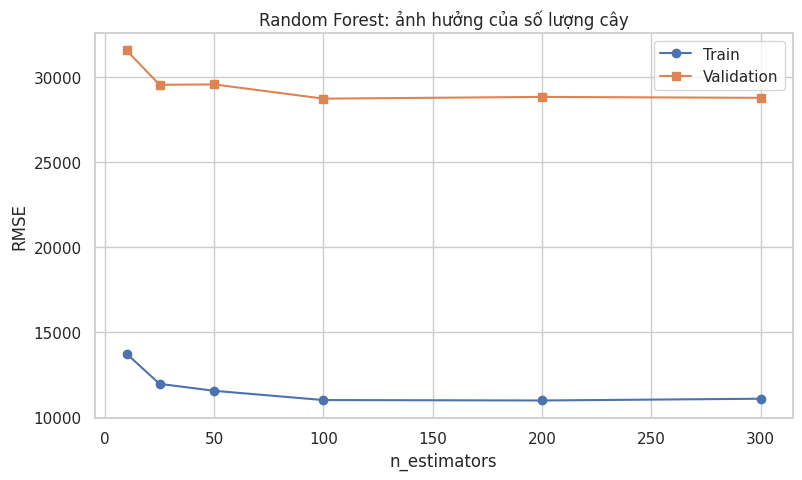

In [105]:
# Vẽ đường RMSE theo số cây
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(n_list, e_tr, "o-", label="Train")
ax.plot(n_list, e_va, "s-", label="Validation")
ax.set_xlabel("n_estimators")
ax.set_ylabel("RMSE")
ax.set_title("Random Forest: ảnh hưởng của số lượng cây")
ax.legend()
luu(fig, "15_rf_n_estimators")

### 3.16. KNN: ảnh hưởng của k và của chuẩn hóa dữ liệu

In [106]:
# Chuẩn hóa dữ liệu về cùng thang đo
# Chỉ học tham số chuẩn hóa từ tập train
scaler = StandardScaler()
X_tr_s = scaler.fit_transform(X_tr.astype(float))
X_val_s = scaler.transform(X_val.astype(float))

In [107]:
# Thử k lẻ từ 1 đến 39 với dữ liệu gốc và dữ liệu đã chuẩn hóa
ks = list(range(1, 41, 2))
raw = []
sca = []

for k in ks:
    knn_a = KNeighborsRegressor(n_neighbors=k).fit(X_tr, y_tr)
    knn_b = KNeighborsRegressor(n_neighbors=k).fit(X_tr_s, y_tr)
    raw.append(rmse(y_val, knn_a.predict(X_val)))
    sca.append(rmse(y_val, knn_b.predict(X_val_s)))

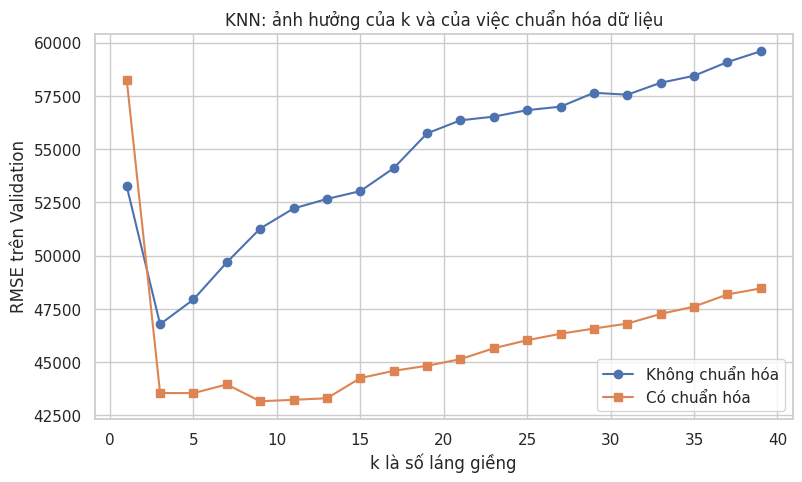

In [108]:
# Vẽ hai đường để so sánh
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(ks, raw, "o-", label="Không chuẩn hóa")
ax.plot(ks, sca, "s-", label="Có chuẩn hóa")
ax.set_xlabel("k là số láng giềng")
ax.set_ylabel("RMSE trên Validation")
ax.set_title("KNN: ảnh hưởng của k và của việc chuẩn hóa dữ liệu")
ax.legend()
luu(fig, "16_knn_k_va_scaling")

### 3.17. Ridge: ảnh hưởng của hệ số điều chuẩn alpha

In [109]:
# Thử các giá trị alpha từ nhỏ đến lớn
alphas = [0.001, 0.01, 0.1, 1, 10, 100, 1000, 10000]
e_tr = []
e_va = []

for a in alphas:
    m = Ridge(alpha=a, random_state=42)
    m.fit(X_tr, y_tr)
    e_tr.append(rmse(y_tr, m.predict(X_tr)))
    e_va.append(rmse(y_val, m.predict(X_val)))

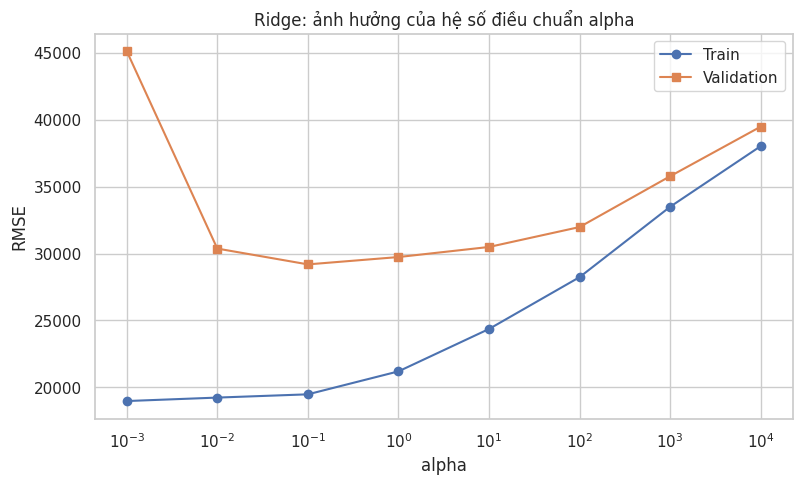

In [110]:
# Vẽ đường RMSE theo alpha với trục hoành dạng log
fig, ax = plt.subplots(figsize=(9, 5))
ax.semilogx(alphas, e_tr, "o-", label="Train")
ax.semilogx(alphas, e_va, "s-", label="Validation")
ax.set_xlabel("alpha")
ax.set_ylabel("RMSE")
ax.set_title("Ridge: ảnh hưởng của hệ số điều chuẩn alpha")
ax.legend()
luu(fig, "17_ridge_alpha")

### 3.18. SVR: ảnh hưởng của tham số C

In [111]:
# Thử các giá trị C, đây là thí nghiệm bổ sung ngoài bảng so sánh chính
c_list = [1, 10, 100, 1000, 10000, 100000]
e_tr = []
e_va = []

for c in c_list:
    m = make_pipeline(StandardScaler(with_mean=False), SVR(C=c))
    m.fit(X_tr, y_tr)
    e_tr.append(rmse(y_tr, m.predict(X_tr)))
    e_va.append(rmse(y_val, m.predict(X_val)))
    print("Xong C =", c, "RMSE Validation =", round(e_va[-1], 2))

Xong C = 1 RMSE Validation = 88667.17
Xong C = 10 RMSE Validation = 88667.06
Xong C = 100 RMSE Validation = 88666.04
Xong C = 1000 RMSE Validation = 88655.84
Xong C = 10000 RMSE Validation = 88553.66
Xong C = 100000 RMSE Validation = 87523.88


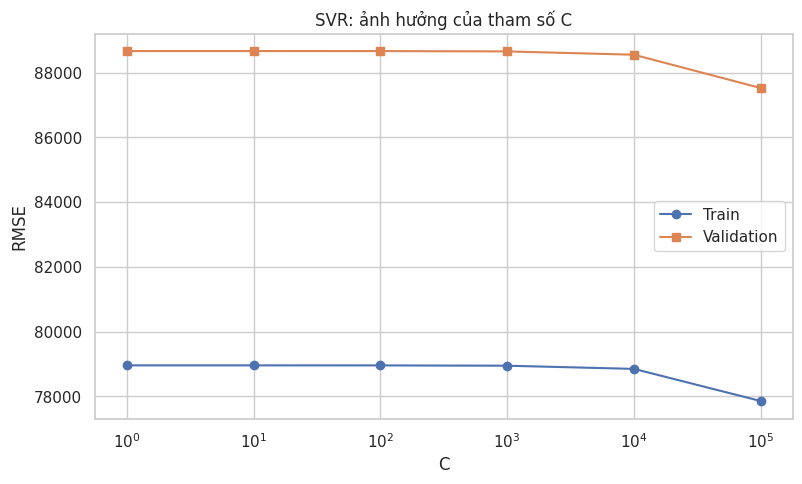

In [112]:
# Vẽ đường RMSE theo C với trục hoành dạng log
fig, ax = plt.subplots(figsize=(9, 5))
ax.semilogx(c_list, e_tr, "o-", label="Train")
ax.semilogx(c_list, e_va, "s-", label="Validation")
ax.set_xlabel("C")
ax.set_ylabel("RMSE")
ax.set_title("SVR: ảnh hưởng của tham số C")
ax.legend()
luu(fig, "18_svr_C")

### 3.19. MLP: đường loss và ảnh hưởng của chuẩn hóa

In [113]:
# Huấn luyện MLP không chuẩn hóa để so với mô hình đã có chuẩn hóa ở trên
mlp_raw = MLPRegressor(hidden_layer_sizes=(100, 50), max_iter=500, random_state=42)
mlp_raw.fit(X_tr, y_tr)

# Lấy mạng MLP bên trong pipeline đã chuẩn hóa
mlp_sca = KQ["MLP"]["model"].named_steps["mlpregressor"]

# Thay giá trị không hợp lệ nếu mạng không chuẩn hóa bị phân kỳ
pred_raw = np.nan_to_num(mlp_raw.predict(X_val), nan=0.0, posinf=1e7, neginf=-1e7)
rmse_raw = rmse(y_val, pred_raw)
rmse_sca = KQ["MLP"]["rmse_val"]

print("RMSE không chuẩn hóa:", round(rmse_raw, 2))
print("RMSE có chuẩn hóa:", round(rmse_sca, 2))

RMSE không chuẩn hóa: 36377.04
RMSE có chuẩn hóa: 38795.69


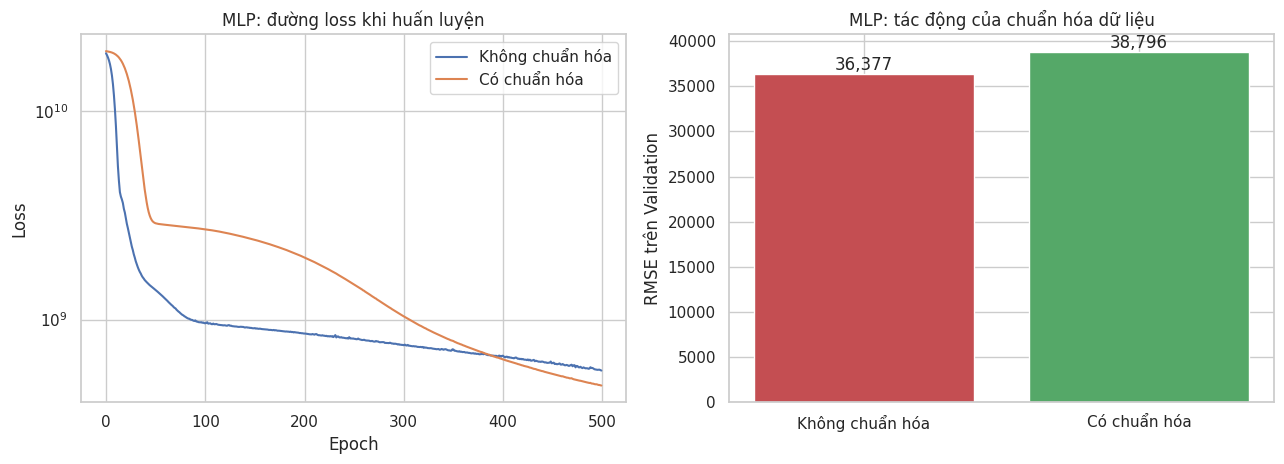

In [114]:
# Vẽ hai hình cạnh nhau, bên trái là đường loss, bên phải là RMSE
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

axes[0].plot(mlp_raw.loss_curve_, label="Không chuẩn hóa")
axes[0].plot(mlp_sca.loss_curve_, label="Có chuẩn hóa")
axes[0].set_yscale("log")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].set_title("MLP: đường loss khi huấn luyện")
axes[0].legend()

bars = axes[1].bar(["Không chuẩn hóa", "Có chuẩn hóa"], [rmse_raw, rmse_sca],
                   color=["#C44E52", "#55A868"])
for b in bars:
    axes[1].text(b.get_x() + b.get_width() / 2, b.get_height() * 1.01,
                 f"{b.get_height():,.0f}", ha="center")
axes[1].set_ylabel("RMSE trên Validation")
axes[1].set_title("MLP: tác động của chuẩn hóa dữ liệu")

fig.tight_layout()
luu(fig, "19_mlp_loss_va_scaling")

### 3.20. AdaBoost và Gradient Boosting: RMSE theo số vòng boosting

In [115]:
# Lấy RMSE sau mỗi vòng boosting của Gradient Boosting
gb = KQ["Gradient Boosting"]["model"]
gb_tr = [rmse(y_tr, p) for p in gb.staged_predict(X_tr)]
gb_va = [rmse(y_val, p) for p in gb.staged_predict(X_val)]

In [116]:
# Lấy RMSE sau mỗi vòng boosting của AdaBoost
ab = KQ["AdaBoost"]["model"]
ab_tr = [rmse(y_tr, p) for p in ab.staged_predict(X_tr)]
ab_va = [rmse(y_val, p) for p in ab.staged_predict(X_val)]

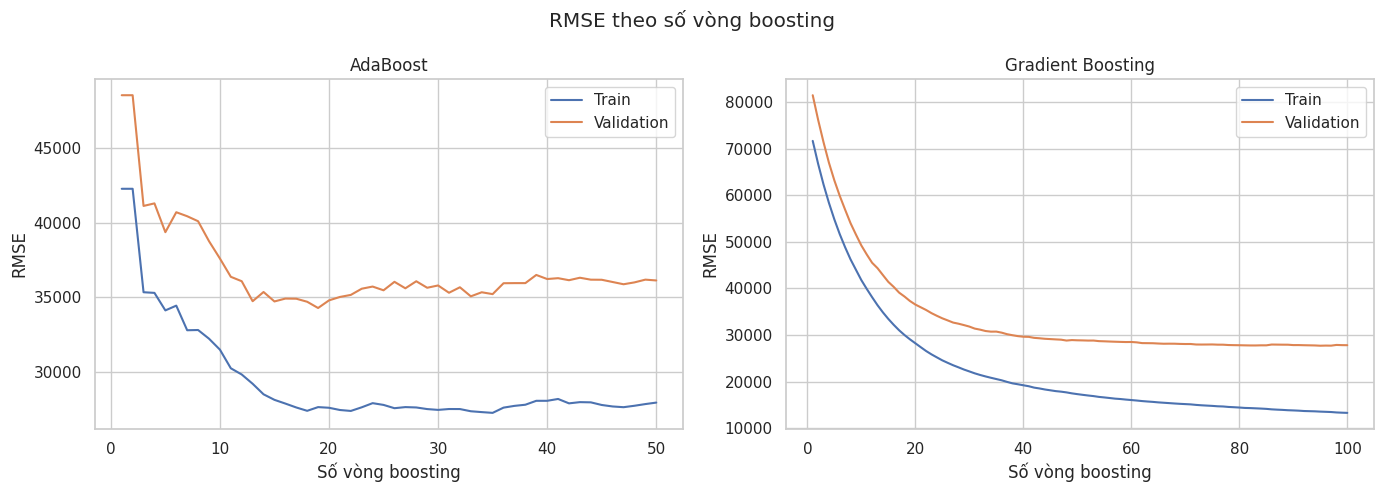

In [117]:
# Vẽ hai hình cạnh nhau, bên trái là AdaBoost, bên phải là Gradient Boosting
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(range(1, len(ab_tr) + 1), ab_tr, label="Train")
axes[0].plot(range(1, len(ab_va) + 1), ab_va, label="Validation")
axes[0].set_xlabel("Số vòng boosting")
axes[0].set_ylabel("RMSE")
axes[0].set_title("AdaBoost")
axes[0].legend()

axes[1].plot(range(1, len(gb_tr) + 1), gb_tr, label="Train")
axes[1].plot(range(1, len(gb_va) + 1), gb_va, label="Validation")
axes[1].set_xlabel("Số vòng boosting")
axes[1].set_ylabel("RMSE")
axes[1].set_title("Gradient Boosting")
axes[1].legend()

fig.suptitle("RMSE theo số vòng boosting")
fig.tight_layout()
luu(fig, "20_boosting_staged")

### 3.21. Learning curve của mô hình tốt nhất

In [118]:
# Tính learning curve với 3 fold và 6 mức kích thước dữ liệu
sizes, tr_s, va_s = learning_curve(
    clone(goc[ten_tot_nhat]), X_train_final, y_train,
    cv=3, train_sizes=np.linspace(0.1, 1.0, 6), n_jobs=-1,
    scoring="neg_root_mean_squared_error"
)

# Đổi dấu để có RMSE dương
tr_s = -tr_s
va_s = -va_s

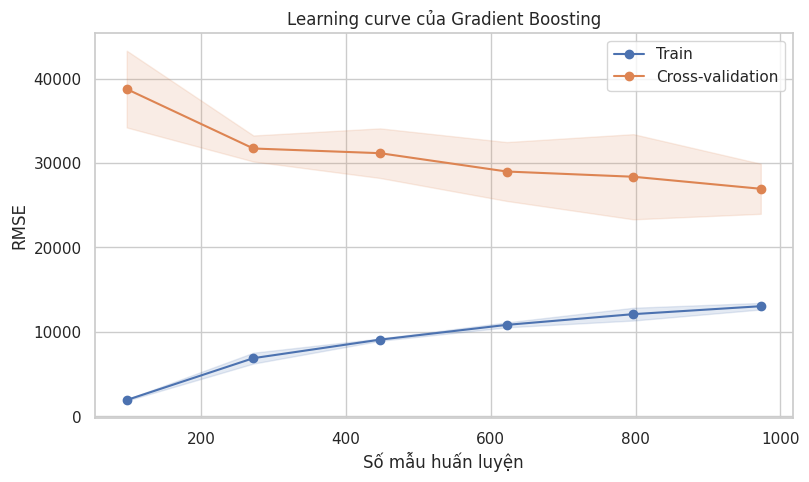

In [119]:
# Vẽ learning curve kèm vùng độ lệch chuẩn
fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(sizes, tr_s.mean(axis=1), "o-", c="#4C72B0", label="Train")
ax.fill_between(sizes, tr_s.mean(axis=1) - tr_s.std(axis=1),
                tr_s.mean(axis=1) + tr_s.std(axis=1), color="#4C72B0", alpha=0.15)

ax.plot(sizes, va_s.mean(axis=1), "o-", c="#DD8452", label="Cross-validation")
ax.fill_between(sizes, va_s.mean(axis=1) - va_s.std(axis=1),
                va_s.mean(axis=1) + va_s.std(axis=1), color="#DD8452", alpha=0.15)

ax.set_xlabel("Số mẫu huấn luyện")
ax.set_ylabel("RMSE")
ax.set_title(f"Learning curve của {ten_tot_nhat}")
ax.legend()
luu(fig, "21_learning_curve")

### 3.22. Bảng tổng hợp kết quả

In [120]:
# Gom kết quả cuối cùng vào một bảng
tong_hop = pd.DataFrame({
    "RMSE Train": {k: KQ[k]["rmse_train"] for k in thu_tu},
    "RMSE Validation": {k: KQ[k]["rmse_val"] for k in thu_tu},
    "MAE Validation": {k: KQ[k]["mae_val"] for k in thu_tu},
    "R2 Validation": {k: KQ[k]["r2_val"] for k in thu_tu},
    "RMSLE Validation": {k: KQ[k]["rmsle_val"] for k in thu_tu},
    "Thời gian huấn luyện": {k: KQ[k]["time"] for k in thu_tu},
}).round(4)

tong_hop.to_csv(f"{THU_MUC}/bang_tong_hop.csv")
display(tong_hop)
print("Đã lưu tất cả hình vào thư mục", THU_MUC)

,RMSE Train,RMSE Validation,MAE Validation,R2 Validation,RMSLE Validation,Thời gian huấn luyện
Gradient Boosting,13299.2108,27819.8655,17161.5573,0.8991,0.1410,1.3568
Extra Trees,0.0000,28205.1827,17798.3496,0.8963,0.1564,4.2382
Random Forest,11027.8401,28713.8284,17618.5511,0.8925,0.1547,4.2655
Ridge,21200.1809,29737.2316,19125.7429,0.8847,0.1653,0.1382
AdaBoost,27949.1861,36134.0073,25836.0339,0.8298,0.2255,0.6814
MLP,31033.6822,38795.6893,23462.8502,0.8038,0.2486,10.1536
Decision Tree,0.0000,43357.9876,27963.7021,0.7549,0.2261,0.0714
KNN,37663.1871,47943.5569,28541.5596,0.7003,0.2289,0.0062
SVR,78961.2318,88667.1712,59568.2273,-0.0250,0.4323,0.2158


Đã lưu tất cả hình vào thư mục hinh_bao_cao
